# 06 · Impacto del pronóstico en el negocio

**Propósito:** estimar cuánto dinero gana o ahorra el negocio al reponer con el pronóstico del CatBoost frente al seasonal naive, en el año de test, de forma global, por segmento y por artículo, en dos escenarios: **A · a un paso** (se vuelve a pronosticar cada mes, como en producción) y **B · encadenado** (los 13 bloques de una vez).

**Contexto (constitución 7.1.0):** el nb 05 midió el test una sola vez (WRMSSE en unidades: a un paso 0,495, encadenado 0,748, seasonal naive 0,868) y lo guardó en `data/interim/nb05_test/`. Aquí no se pronostica ni se mide el error otra vez: se traduce esa medición a dinero. El objetivo del pronóstico es no quedarse corto (evitar quiebres) sin inmovilizar plata de más.

**Etapas** (el estado de cada una vive en `specs/001-abc-xyz-share-forecast/nb06-etapas.md`):

| # | Etapa |
|---|---|
| 0 | Decisiones y reglas |
| 1 | Carga, precio por bloque y demanda cruda frente a tratada |
| 2 | Disponible y métricas en dinero para cada colchón z |
| 3 | Curvas de intercambio e impacto global y por segmento: A · a un paso, B · encadenado, A frente a B |
| 4 | Impacto por artículo, mayores y menores: A · a un paso, B · encadenado |
| 5 | Guardado y cierre |


## Etapa 0 · Decisiones y reglas

**Objetivo:** fijar qué hace este notebook y con qué reglas, antes de escribir código.

**Decisiones propuestas:**

| # | Decisión | Justificación |
|---|---|---|
| D1 | **Entradas, cargadas y no recalculadas (R5):** `data/interim/nb05_test/` (`forecasts`, `item_metrics`, manifiesto), del nb 03b `rmsse_scale` y `snaive_valid` (seasonal naive en la ventana de backtesting), y los intermedios diarios por artículo (`item_units`, `item_spend`) hasta el último día de datos. | Principio VI y constitución 7.1.0: el nb 06 solo lee la medición del nb 05; no vuelve a pronosticar. |
| D2 | **Demanda = serie tratada** (usuario, 2026-11-10): las unidades del test de `forecasts`. La venta cruda solo se usa en la Etapa 1 para medir cuánto difieren (unidades y dinero), como advertencia. | En un quiebre la venta cruda subestima la demanda: un pronóstico que acierta aparecería como exceso y la venta perdida por quiebre no se vería. Es además la serie con la que se entrenó y midió el modelo. |
| D3 | **Precio por artículo y bloque de test** = gasto crudo / unidades crudas del bloque (precio de venta promedio, ponderado por tienda); si el bloque no tiene ventas crudas, el del último bloque con ventas. | Los datos traen precio de venta, no costo ni margen: todo se valora a precio de venta y se habla de venta (revenue), no de ganancia. |
| D4 | **Pronósticos comparados y dos escenarios con el mismo peso (usuario, 2026-11-10):** **A · a un paso**, se vuelve a pronosticar cada mes (la política habitual de las empresas) y cada bloque usa lo último observado; **B · encadenado**, los 13 bloques se pronostican de una vez desde el inicio del test. En los dos, frente al **seasonal naive** (línea base, el mismo en ambos) y al **perfecto** (disponible = demanda; techo de lo alcanzable). Cada escenario tiene su propia sección en las Etapas 3 y 4, con las mismas tablas y gráficos, y al final una comparación A frente a B. | A es lo que se hará en producción; B muestra cuánto se pierde si no se renueva el pronóstico. El perfecto permite decir qué parte de lo alcanzable recupera cada escenario. |
| D5 | **Colchón:** disponible = max(pronóstico + z·σ, 0). σ = RMSE del artículo en la ventana de backtesting de esa forma: CatBoost = RMSSE de la ventana (`item_metrics`) × escala del RMSSE; seasonal naive = RMSE de `snaive_valid`; perfecto σ = 0. | Constitución 7.1.0: σ nunca sale del test. El RMSE incluye el sesgo, que también hay que cubrir. |
| D6 | **z de −1 a 3 cada 0,25** (17 valores). Cada bloque se evalúa por separado: sin tiempo de entrega, sin stock inicial y sin arrastrar lo que sobra al bloque siguiente (usuario). | z = 0 es el pronóstico puro; los negativos muestran el efecto de quedarse corto; 3 equivale a ~99,9 % de servicio con errores normales y más allá no cambia la lectura. Evaluar bloque a bloque no inventa una operación que no está definida en el proyecto. |
| D7 | **Métricas por artículo, bloque, forma y z**, a precio de venta: venta capturada = min(disponible, demanda)·p; venta perdida = max(demanda − disponible, 0)·p; exceso = max(disponible − demanda, 0)·p; nivel de servicio = capturada / demanda (en dinero). | Responden lo que interesa: cuánta venta se atiende, cuánta se pierde por quedarse corto y cuánta plata queda inmovilizada por quedarse largo. |
| D8 | **Curvas de intercambio:** exceso (eje X) frente a venta perdida (eje Y), una curva por pronóstico, global y por segmento, en cada escenario (A y B). **Lecturas a igual servicio**, con un objetivo de **95 %** (z de cada pronóstico interpolado en la curva): exceso que se ahorra y venta que se recupera frente al seasonal naive, y qué parte de lo alcanzable recupera (frente al perfecto). También a z = 0. Al final, A frente a B: cuánta plata vale renovar el pronóstico cada mes. | La curva no necesita costos: si la del modelo queda por debajo, es mejor para cualquier colchón. El 95 % es un objetivo de servicio habitual en retail y la curva permite leer cualquier otro. |
| D9 | **Impacto por artículo, en cada escenario (A y B):** al z de cada pronóstico que da el 95 % global, desajuste = venta perdida + exceso; impacto = desajuste del seasonal naive − desajuste del CatBoost (positivo = el modelo mejora), con sus dos componentes por separado. Ranking: los 10 de mayor y los 10 de menor impacto, cruzados con segmento y RMSSE del nb 05, y en pantalla el gráfico del nb 05 de los 5 mayores y los 5 menores. | Muestra dónde se concentra la ganancia y dónde el modelo no aporta o empeora. Sumar perdida y exceso uno a uno es un supuesto (mismo costo por peso), por eso se muestran también por separado. |
| D10 | **Salidas:** `data/interim/nb06_impact/` con `curves.parquet` (forma × segmento × z), `item_impact.parquet` (artículo × escenario, al 95 %) y manifiesto (`save_tables`), con candado (`RERUN`/`OVERWRITE`). | Insumo del informe final en `reports/` sin recalcular. |
| D11 | **Lo que no hace:** no cambia datos, variables, hiperparámetros ni el modelo, y ningún resultado de este notebook alimenta una decisión del modelo. | Constitución 7.1.0: el impacto es descriptivo. |
| D12 | **Cómputo:** sin piloto (R7): 6.721 filas × 4 formas × 17 valores de z ≈ 460 mil filas, en segundos y en memoria. | Operaciones vectorizadas sobre tablas ya cargadas. |

**Reglas que se mantienen:** R1–R8 de `CLAUDE.md`.


## Configuración

**Qué hace:** fija la raíz del proyecto (rutas relativas), activa `%autoreload`, carga la configuración validada, fija la semilla e imprime las versiones (R6).


In [20]:
%load_ext autoreload
%autoreload 2

import os
import platform
import sys
from importlib.metadata import version
from pathlib import Path

# Raíz del código: el notebook corre desde notebooks/.
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT))
os.chdir(os.environ.get("PROJECT_ROOT", CODE_ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import load_validated_config

pd.set_option("display.max_columns", 30)

cfg = load_validated_config()
SEED = cfg["features"]["seed"]

LIBS = ["numpy", "pandas", "pyarrow", "catboost"]
display(pd.Series({"python": platform.python_version(), **{lib: version(lib) for lib in LIBS}}, name="versión").to_frame())
print(f"semilla: {SEED}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,versión
python,3.12.3
numpy,2.5.4
pandas,3.1.0
pyarrow,26.0.0
catboost,1.2.10


semilla: 42


## Candado

**Qué hace:** si las salidas del notebook ya existen, se detiene salvo `RERUN = True`; `OVERWRITE = True` solo para reemplazarlas (D10).


In [21]:
from src.data import guard_rerun

OUT_DIR = Path("data/interim/nb06_impact")   # D10: salida del notebook
RERUN = False       # True para volver a ejecutar aunque existan las salidas
OVERWRITE = False   # True solo para reemplazar lo guardado
guard_rerun([OUT_DIR / "manifest.json"], RERUN)


[]

## Etapa 1 · Carga, precio por bloque y demanda cruda frente a tratada

**Objetivo:** dejar en una tabla, por artículo y bloque de test, la demanda (tratada), el precio y los pronósticos, y en otra el σ de cada artículo y pronóstico; y medir cuánto difiere la venta cruda de la demanda tratada (D1, D2, D3, D5).
**Entradas:**
- `data/interim/nb05_test/` (nb 05): `forecasts` (demanda tratada y pronósticos del test) e `item_metrics` (RMSSE de cada artículo en la ventana de backtesting) y su manifiesto.
- `data/interim/nb03b_datasets/` (nb 03b): `boosting_data` (fechas de cada bloque, train y test), `rmsse_scale` y `snaive_valid` (seasonal naive en la ventana de backtesting).
- Intermedios diarios por artículo (`item_units`, `item_spend`) hasta el último día de datos y el calendario.

**Salidas:**
- `demand`: una fila por artículo y bloque de test con `units` (demanda tratada), `units_raw` y `spend_raw` (venta cruda), `price` y los pronósticos en unidades (`units_1step`, `units_chain`, `units_snaive`).
- `sigma`: una fila por artículo con el σ de cada pronóstico (`sigma_1step`, `sigma_chain`, `sigma_snaive`).
- `raw_gap`: diferencia entre la demanda tratada y la venta cruda, en unidades y en dinero, por segmento.

**Decisión:**
- **Precio (D3):** gasto crudo / unidades crudas de cada bloque, con la serie completa del artículo (train y test); si un bloque no tiene ventas crudas, el precio del último bloque anterior con ventas. Los días enmascarados no suman venta (cuentan como 0 observado).
- **σ (D5), siempre de la ventana de backtesting:** CatBoost = RMSSE de la ventana (`item_metrics`) × √escala del RMSSE (03b): la escala es un error al cuadrado, así que así se vuelve al RMSE en unidades; seasonal naive = raíz del error cuadrático medio de `snaive_valid`.
- **Cruda frente a tratada (D2):** solo se mide y se muestra, como advertencia; no entra en el cálculo del impacto.
- **Chequeos:** 517 × 13 filas, una por artículo y bloque, iguales a las del nb 05; precio positivo y sin nulos; σ positivo y sin nulos, y del mismo orden que el del seasonal naive (mediana de la razón entre 0,2 y 2); la venta cruda no es negativa; la diferencia cruda frente a tratada se reporta con signo.


In [22]:
from src.data import load_calendar, load_interim, load_tables
from src.features import BLOCK_DAYS
from src.metrics import block_totals

NB05_DIR = Path("data/interim/nb05_test")            # nb 05: medición del test
DATASETS_DIR = Path("data/interim/nb03b_datasets")   # nb 03b: datasets, escalas y seasonal naive de la ventana
SEGMENTS = ["AX", "AY", "AZ"]


In [23]:
nb05, nb05_manifest = load_tables(NB05_DIR)
inputs, manifest = load_tables(DATASETS_DIR)
forecasts, item_metrics = nb05["forecasts"], nb05["item_metrics"]
boosting_data = inputs["boosting_data"]
rmsse_scale = inputs["rmsse_scale"].set_index("item_id")["scale"]

# Venta cruda por bloque (toda la serie, para poder arrastrar el precio) y precio (D3).
cal = load_calendar(cfg)
day_of = pd.Series(cal["d"].str[2:].astype(int).to_numpy(), index=pd.to_datetime(cal["date"]))   # fecha → día d
interim = load_interim(cfg, max_day=cfg["data"]["last_day"])   # incluye el test: solo se valora, no se entrena nada
blocks = boosting_data[["item_id", "block", "start_date", "split"]].assign(item_id=lambda d: d["item_id"].astype(str))
blocks["units_raw"] = block_totals(interim["item_units"], interim["item_ids"], blocks, day_of, BLOCK_DAYS)
blocks["spend_raw"] = block_totals(interim["item_spend"], interim["item_ids"], blocks, day_of, BLOCK_DAYS)
blocks = blocks.sort_values(["item_id", "block"], ignore_index=True)
blocks["price"] = (blocks["spend_raw"] / blocks["units_raw"].where(blocks["units_raw"] > 0)).groupby(blocks["item_id"]).ffill()

demand = (forecasts[["item_id", "block", "step", "cell", "units", "units_1step", "units_chain", "units_snaive"]]
          .merge(blocks[["item_id", "block", "units_raw", "spend_raw", "price"]], on=["item_id", "block"], how="left",
                 validate="one_to_one")
          .sort_values(["item_id", "block"], ignore_index=True))

# σ por artículo y pronóstico, de la ventana de backtesting (D5).
# La escala del RMSSE es un error al cuadrado: RMSE = RMSSE × √escala.
sigma_cb = (item_metrics.pivot(index="item_id", columns="form", values="rmsse_units_window")
            .mul(np.sqrt(rmsse_scale), axis=0).rename(columns={"a un paso": "sigma_1step", "encadenado": "sigma_chain"}))
snaive_valid = inputs["snaive_valid"].assign(item_id=lambda d: d["item_id"].astype(str))
sigma_sn = snaive_valid.groupby("item_id")["error"].apply(lambda e: float(np.sqrt(np.mean(np.square(e))))).rename("sigma_snaive")
sigma = sigma_cb.join(sigma_sn).reindex(sorted(demand["item_id"].unique()))

# Demanda tratada frente a venta cruda (D2, solo advertencia).
gap = demand.assign(gap_units=demand["units"] - demand["units_raw"],
                    gap_money=(demand["units"] - demand["units_raw"]) * demand["price"],
                    money=demand["units"] * demand["price"], changed=~np.isclose(demand["units"], demand["units_raw"]))
raw_gap = pd.concat([gap, gap.assign(cell="total")]).groupby("cell").agg(
    bloques=("changed", "size"), bloques_distintos=("changed", "sum"), dif_unidades=("gap_units", "sum"),
    dif_dinero=("gap_money", "sum"), demanda_dinero=("money", "sum"))
raw_gap["dif_%"] = 100 * raw_gap["dif_dinero"] / raw_gap["demanda_dinero"]


In [24]:
n_items = demand["item_id"].nunique()
assert len(demand) == len(forecasts) == n_items * nb05_manifest["n_test"] and n_items == nb05_manifest["n_items"]
assert not demand.duplicated(["item_id", "block"]).any()
assert demand[["units", "units_1step", "units_chain", "units_snaive", "units_raw", "spend_raw", "price"]].notna().all().all()
assert (demand["price"] > 0).all() and (demand["units_raw"] >= 0).all()
assert sigma.notna().all().all() and (sigma > 0).all().all() and len(sigma) == n_items
# Coherencia con el backtesting: el σ del CatBoost a un paso debe ser del orden del del seasonal naive
# (en la ventana, WRMSSE 0,506 frente a 0,894); una razón lejos de 1 delata un error de unidades.
sigma_ratio = float((sigma["sigma_1step"] / sigma["sigma_snaive"]).median())
assert 0.2 < sigma_ratio < 2, sigma_ratio
print(f"mediana σ a un paso / σ seasonal naive: {sigma_ratio:.2f}")

print(f"nb 05: {nb05_manifest['saved_at']} · {n_items} artículos × {nb05_manifest['n_test']} bloques de test")
print("Precio por bloque de test (por artículo, en dinero):")
display(demand.groupby("cell")["price"].describe(percentiles=[0.1, 0.5, 0.9]).round(2))
print("σ por artículo (unidades), de la ventana de backtesting:")
display(sigma.join(demand.groupby("item_id")["cell"].first()).groupby("cell").median().round(1).rename_axis("mediana por segmento"))
print("Demanda tratada frente a venta cruda en el test (positivo = la tratada es mayor):")
display(raw_gap.round({"dif_unidades": 0, "dif_dinero": 0, "demanda_dinero": 0, "dif_%": 2}))
display(demand.sample(5, random_state=SEED).round(2))


mediana σ a un paso / σ seasonal naive: 0.55
nb 05: 2026-11-10T16:39:25 · 517 artículos × 13 bloques de test
Precio por bloque de test (por artículo, en dinero):


,count,mean,std,min,10%,50%,90%,max
cell,,,,,,,,
AX,2483.0,5.70,4.85,0.68,1.68,4.18,11.28,29.02
AY,2977.0,5.04,3.68,0.79,1.00,3.98,9.97,18.92
AZ,1261.0,4.35,3.13,0.84,0.99,3.54,9.94,12.78


σ por artículo (unidades), de la ventana de backtesting:


,sigma_1step,sigma_chain,sigma_snaive
mediana por segmento,,,
AX,45.1,54.8,73.0
AY,72.5,105.1,135.3
AZ,144.9,248.8,323.1


Demanda tratada frente a venta cruda en el test (positivo = la tratada es mayor):


,bloques,bloques_distintos,dif_unidades,dif_dinero,demanda_dinero,dif_%
cell,,,,,,
AX,2483,1202,116175.0,489224.0,7579963.0,6.45
AY,2977,1654,287751.0,863677.0,9851338.0,8.77
AZ,1261,767,290388.0,689120.0,4424915.0,15.57
total,6721,3623,694314.0,2042021.0,21856216.0,9.34


,item_id,block,step,cell,units,units_1step,units_chain,units_snaive,units_raw,spend_raw,price
3552,FOODS_3_727,56,4,AY,768.50,946.52,785.51,796.00,462.0,1696.45,3.67
4108,HOBBIES_1_100,53,1,AX,110.21,106.26,106.26,95.00,104.0,1173.12,11.28
549,FOODS_2_022,56,4,AZ,384.29,431.91,551.85,490.50,384.0,2680.32,6.98
1163,FOODS_2_322,59,7,AX,887.82,839.86,750.01,791.00,777.0,2260.54,2.91
1881,FOODS_3_224,62,10,AZ,499.54,437.25,480.73,514.43,471.0,1908.08,4.05


## Etapa 2 · Disponible y métricas en dinero para cada colchón z

**Objetivo:** para cada pronóstico y cada colchón z, calcular por artículo cuánta venta se captura, cuánta se pierde y cuánto sobra, en dinero (D5, D6, D7). Es la base de las curvas (Etapa 3) y del impacto por artículo (Etapa 4).
**Entradas:** `demand` y `sigma` (Etapa 1).
**Salidas:** `coverage`, una fila por artículo, pronóstico y z con `demand`, `captured`, `lost`, `excess` (dinero, sumado en los 13 bloques) y `short_blocks` (bloques en los que se quedó corto).

**Decisión:**
- **Pronósticos:** `a un paso`, `encadenado`, `seasonal naive` (cada uno con su σ de la ventana de backtesting) y `perfecto` (disponible = demanda, σ = 0). El seasonal naive y el perfecto sirven para los dos escenarios.
- **Disponible = max(pronóstico + z·σ, 0)**, bloque a bloque, sin arrastrar lo que sobra (D6). Nunca negativo: no se puede tener inventario negativo.
- **z de −1 a 3 cada 0,25** (D6): 17 valores.
- **Montos a precio de venta** (D3): capturada + perdida = demanda en dinero, en cada fila.
- **Chequeos:** 517 × 4 pronósticos × 17 z filas; capturada + perdida = demanda; el perfecto no pierde ni sobra; al subir z la venta perdida no sube y el exceso no baja (por artículo y pronóstico); sin nulos.


In [25]:
from src.metrics import coverage_by_z

Z_VALUES = np.round(np.arange(-1.0, 3.0 + 1e-9, 0.25), 2)   # D6: −1 a 3 cada 0,25
FORECASTS = {"a un paso": "units_1step", "encadenado": "units_chain", "seasonal naive": "units_snaive", "perfecto": "units"}
SIGMA = {"a un paso": sigma["sigma_1step"], "encadenado": sigma["sigma_chain"], "seasonal naive": sigma["sigma_snaive"]}


In [26]:
coverage = coverage_by_z(demand, FORECASTS, SIGMA, Z_VALUES)
coverage["cell"] = coverage["item_id"].map(demand.groupby("item_id")["cell"].first())


In [27]:
assert len(Z_VALUES) == 17 and len(coverage) == n_items * len(FORECASTS) * len(Z_VALUES)
assert coverage.notna().all().all() and not coverage.duplicated(["item_id", "forecast", "z"]).any()
assert np.allclose(coverage["captured"] + coverage["lost"], coverage["demand"])
perfect = coverage[coverage["forecast"] == "perfecto"]
assert np.allclose(perfect[["lost", "excess"]], 0)
by_z = coverage.sort_values(["item_id", "forecast", "z"]).groupby(["item_id", "forecast"])
assert (by_z["lost"].diff().dropna() <= 1e-9).all() and (by_z["excess"].diff().dropna() >= -1e-9).all()
total_demand = demand["units"].mul(demand["price"]).sum()
assert np.allclose(coverage.groupby(["forecast", "z"])["demand"].sum(), total_demand)

totals = coverage.groupby(["forecast", "z"])[["captured", "lost", "excess", "short_blocks"]].sum()
totals["service_%"] = 100 * totals["captured"] / total_demand
print(f"demanda del test en dinero (tratada × precio): {total_demand:,.0f}")
print("Totales sin colchón (z = 0):")
display(totals.xs(0.0, level="z").round({"captured": 0, "lost": 0, "excess": 0, "service_%": 2}))
print("Nivel de servicio (%) según z:")
display(totals["service_%"].unstack("z").round(1))


demanda del test en dinero (tratada × precio): 21,856,216
Totales sin colchón (z = 0):


,captured,lost,excess,short_blocks,service_%
forecast,,,,,
a un paso,20782005.0,1074210.0,966803.0,3242,95.09
encadenado,19898626.0,1957590.0,1417016.0,3428,91.04
perfecto,21856216.0,0.0,0.0,0,100.00
seasonal naive,19273022.0,2583194.0,1546791.0,3829,88.18


Nivel de servicio (%) según z:


z,-1.00,-0.75,-0.50,-0.25,0.00,0.25,0.50,0.75,1.00,1.25,1.50,1.75,2.00,2.25,2.50,2.75,3.00
forecast,,,,,,,,,,,,,,,,,
a un paso,85.8,88.6,91.1,93.3,95.1,96.4,97.3,98.0,98.5,98.9,99.2,99.4,99.5,99.6,99.7,99.8,99.8
encadenado,75.8,80.0,84.1,87.9,91.0,93.2,94.7,95.8,96.7,97.4,97.9,98.4,98.7,98.9,99.1,99.3,99.4
perfecto,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
seasonal naive,67.9,73.4,78.8,83.9,88.2,91.3,93.6,95.3,96.5,97.5,98.2,98.6,99.0,99.2,99.4,99.5,99.6


## Etapa 3 · Curvas de intercambio e impacto global y por segmento

**Objetivo:** pasar `coverage` a curvas (exceso frente a venta perdida al variar z), global y por segmento, y leer en ellas cuánto dinero ahorra o recupera el CatBoost frente al seasonal naive en cada escenario: **A · a un paso** y **B · encadenado**; al final, A frente a B (D4, D8).
**Entradas:** `coverage` y `demand` (Etapas 1 y 2).
**Salidas:** `curves` (segmento × pronóstico × z, con servicio), `readings` (lecturas por escenario y segmento) y `ab` (A frente a B).

**Cómo leer las curvas:** cada punto es un colchón z; el eje vertical se recorta a la zona entre z = 0 y el 95 % (con z negativos la venta perdida llega a toda la demanda); hacia la derecha se tiene más disponible (más exceso, menos venta perdida). Más abajo y a la izquierda es mejor; el perfecto es el origen. Si la curva del CatBoost queda por debajo de la del seasonal naive, el modelo es mejor con cualquier colchón que se elija.

**Lecturas por escenario y segmento:**
- **Al 95 % de servicio** (objetivo, D8): z de cada pronóstico que lo alcanza (interpolado; sin extrapolar fuera de −1 a 3), su exceso y el **ahorro de exceso** = exceso del seasonal naive − exceso del CatBoost (a igual servicio la venta perdida es la misma, el 5 % de la demanda: la diferencia está en la plata inmovilizada).
- **Venta recuperada a igual exceso:** con el exceso que necesita el seasonal naive para el 95 %, cuánta venta pierde el CatBoost; recuperada = venta perdida del seasonal naive − la del CatBoost.
- **Sin colchón (z = 0):** venta perdida y exceso de cada uno.
- **Recuperación de lo alcanzable** = 1 − desajuste del CatBoost / desajuste del seasonal naive (desajuste = perdida + exceso; el perfecto tiene 0), a z = 0 y al 95 %.
- **A frente a B:** cuánto exceso más necesita el encadenado para el mismo 95 % y cuánto desajuste más tiene a z = 0: lo que vale volver a pronosticar cada mes.


In [28]:
import matplotlib.pyplot as plt

from src.metrics import lost_at_excess, service_reading
from src.modeling import plot_tradeoff_curves

TARGET_SERVICE = 0.95                            # D8: objetivo de servicio habitual en retail
SEG_ALL = ["total", *SEGMENTS]
SCENARIOS = {"A · a un paso": "a un paso", "B · encadenado": "encadenado"}
BASE = "seasonal naive"


In [29]:
cov_seg = pd.concat([coverage, coverage.assign(cell="total")])
curves = (cov_seg.groupby(["cell", "forecast", "z"])[["demand", "captured", "lost", "excess", "short_blocks"]].sum()
          .reset_index().rename(columns={"cell": "segment"}))
curves["service"] = curves["captured"] / curves["demand"]
curve = lambda seg, name: curves[(curves["segment"] == seg) & (curves["forecast"] == name)]

def scenario_readings(model):
    rows, marks = [], []
    for seg in SEG_ALL:
        m95, b95 = service_reading(curve(seg, model), TARGET_SERVICE), service_reading(curve(seg, BASE), TARGET_SERVICE)
        m0, b0 = curve(seg, model).set_index("z").loc[0.0], curve(seg, BASE).set_index("z").loc[0.0]
        lost_same = lost_at_excess(curve(seg, model), b95["excess"])
        rows.append({"segment": seg, "z95_modelo": m95["z"], "z95_naive": b95["z"],
                     "exceso95_modelo": m95["excess"], "exceso95_naive": b95["excess"],
                     "ahorro_exceso95": b95["excess"] - m95["excess"],
                     "ahorro_exceso95_%": 100 * (b95["excess"] - m95["excess"]) / b95["excess"],
                     "venta_recuperada_igual_exceso": b95["lost"] - lost_same,
                     "perdida0_modelo": m0["lost"], "perdida0_naive": b0["lost"],
                     "exceso0_modelo": m0["excess"], "exceso0_naive": b0["excess"],
                     "recupera0_%": 100 * (1 - (m0["lost"] + m0["excess"]) / (b0["lost"] + b0["excess"])),
                     "recupera95_%": 100 * (1 - (m95["lost"] + m95["excess"]) / (b95["lost"] + b95["excess"]))})
        marks += [{"segment": seg, "forecast": f, "lost": r["lost"], "excess": r["excess"]} for f, r in ((model, m95), (BASE, b95))]
    return pd.DataFrame(rows).set_index("segment"), pd.DataFrame(marks)

readings, marks = {}, {}
for scen, model in SCENARIOS.items():
    readings[scen], marks[scen] = scenario_readings(model)

a, b = readings["A · a un paso"], readings["B · encadenado"]
ab = pd.DataFrame({"exceso95_A": a["exceso95_modelo"], "exceso95_B": b["exceso95_modelo"],
                   "exceso95_extra_B": b["exceso95_modelo"] - a["exceso95_modelo"],
                   "desajuste0_A": a["perdida0_modelo"] + a["exceso0_modelo"],
                   "desajuste0_B": b["perdida0_modelo"] + b["exceso0_modelo"]})
ab["desajuste0_extra_B"] = ab["desajuste0_B"] - ab["desajuste0_A"]


In [30]:
assert len(curves) == len(SEG_ALL) * len(FORECASTS) * len(Z_VALUES)
assert np.allclose(curves.groupby(["segment", "forecast", "z"])["demand"].sum().xs("total", level="segment"), total_demand)
for scen, r in readings.items():
    assert len(r) == len(SEG_ALL), scen
    missing = r[["z95_modelo", "z95_naive"]].isna()
    if missing.any().any():   # el 95 % no se alcanza con z entre −1 y 3: se informa, no se extrapola
        print(f"{scen}: sin lectura al 95 % en", missing[missing.any(axis=1)].index.tolist())
assert readings["A · a un paso"].loc["total", ["z95_modelo", "z95_naive"]].notna().all()

print(f"demanda del test en dinero: {total_demand:,.0f}")
display(curves[np.isclose(curves["z"], 0)].pivot(index="segment", columns="forecast", values="service").reindex(SEG_ALL).mul(100).round(1)
        .rename_axis("servicio % a z = 0"))


demanda del test en dinero: 21,856,216


forecast,a un paso,encadenado,perfecto,seasonal naive
servicio % a z = 0,,,,
total,95.1,91.0,100.0,88.2
AX,95.8,92.3,100.0,91.1
AY,95.2,91.9,100.0,87.9
AZ,93.6,86.8,100.0,83.7


### A · a un paso (se vuelve a pronosticar cada mes)


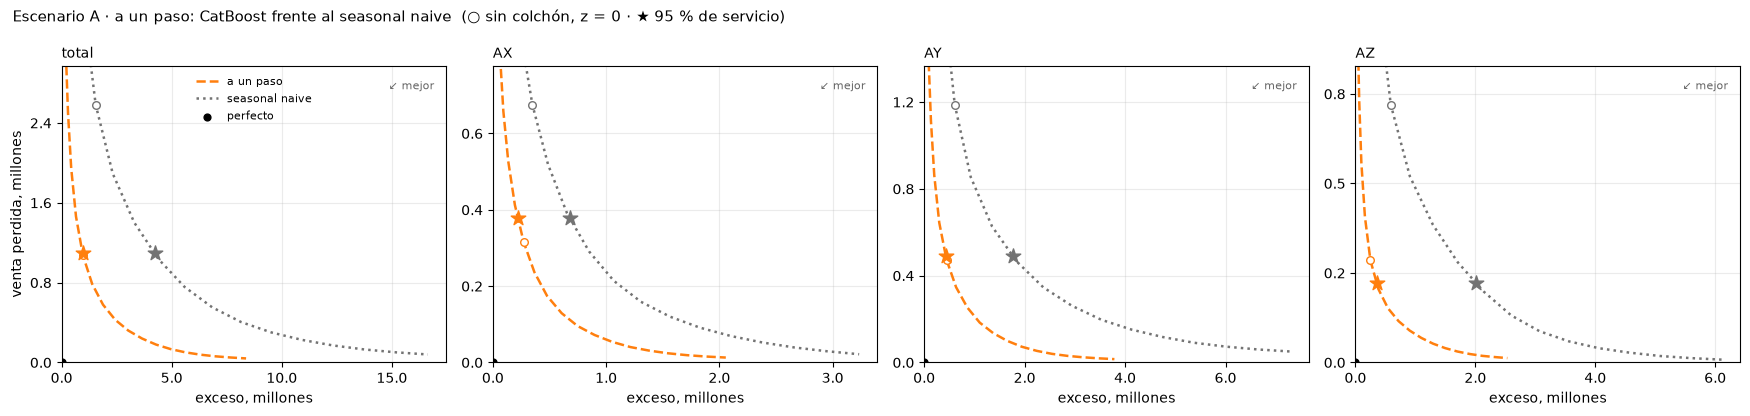

segment,total,AX,AY,AZ
z95_modelo,-0.01,-0.16,-0.03,0.20
z95_naive,0.71,0.53,0.71,0.93
exceso95_modelo,951800.51,221048.11,429212.13,356014.14
exceso95_naive,4227962.85,678040.89,1759565.65,2016929.69
ahorro_exceso95,3276162.34,456992.78,1330353.52,1660915.55
ahorro_exceso95_%,77.49,67.40,75.61,82.35
venta_recuperada_igual_exceso,907451.60,266767.99,402758.03,200263.87
perdida0_modelo,1074210.36,315797.51,473183.48,285229.37
perdida0_naive,2583193.79,675438.45,1187807.42,719947.92
exceso0_modelo,966803.41,271441.73,445680.03,249681.65


Al 95% de servicio, el CatBoost necesita 951,801 de exceso frente a 4,227,963 del seasonal naive: libera 3,276,162 (77.5 %).
Con el mismo exceso que el seasonal naive, recupera 907,452 de venta.
Sin colchón pierde 1,074,210 (naive 2,583,194) y sobra 966,803 (naive 1,546,791); recupera el 50.6 % de lo alcanzable.


In [31]:
scen = "A · a un paso"
fig = plot_tradeoff_curves(curves, [SCENARIOS[scen], BASE], SEG_ALL, marks[scen], f"Escenario {scen}: CatBoost frente al seasonal naive")
plt.show()
display(readings[scen].T.round(2))
r = readings[scen].loc["total"]
print(f"Al {TARGET_SERVICE:.0%} de servicio, el CatBoost necesita {r['exceso95_modelo']:,.0f} de exceso frente a {r['exceso95_naive']:,.0f} "
      f"del seasonal naive: libera {r['ahorro_exceso95']:,.0f} ({r['ahorro_exceso95_%']:.1f} %).")
print(f"Con el mismo exceso que el seasonal naive, recupera {r['venta_recuperada_igual_exceso']:,.0f} de venta.")
print(f"Sin colchón pierde {r['perdida0_modelo']:,.0f} (naive {r['perdida0_naive']:,.0f}) y sobra {r['exceso0_modelo']:,.0f} "
      f"(naive {r['exceso0_naive']:,.0f}); recupera el {r['recupera0_%']:.1f} % de lo alcanzable.")


### B · encadenado (13 bloques de una vez)


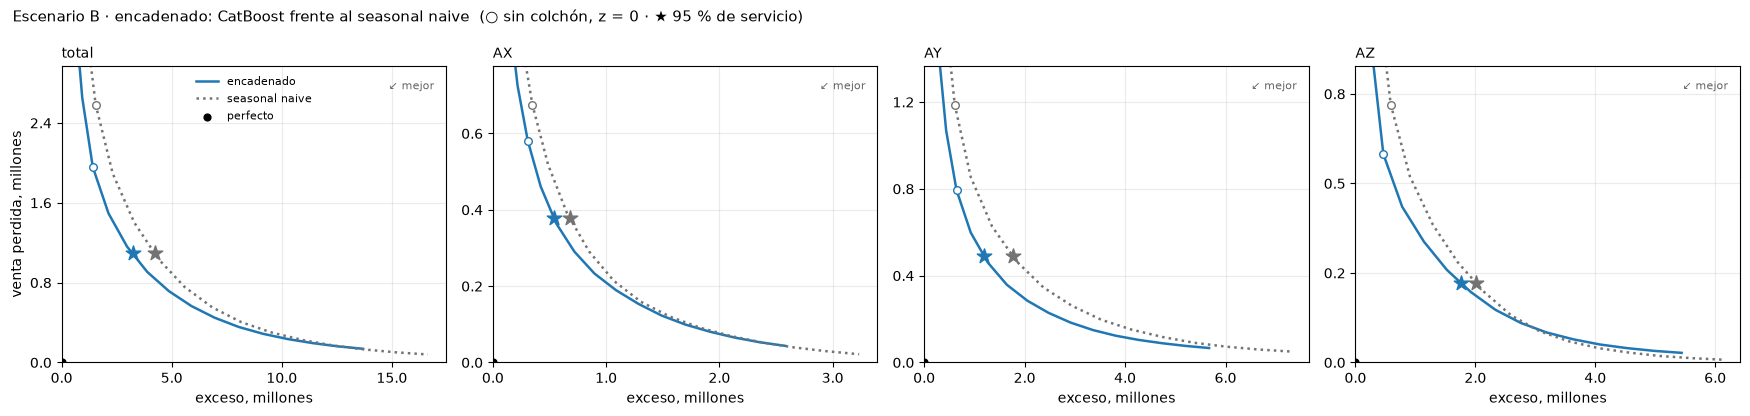

segment,total,AX,AY,AZ
z95_modelo,0.57,0.46,0.44,0.90
z95_naive,0.71,0.53,0.71,0.93
exceso95_modelo,3219791.77,538680.53,1188629.90,1766306.05
exceso95_naive,4227962.85,678040.89,1759565.65,2016929.69
ahorro_exceso95,1008171.08,139360.36,570935.75,250623.64
ahorro_exceso95_%,23.85,20.55,32.45,12.43
venta_recuperada_igual_exceso,251610.72,69374.26,154784.64,35650.80
perdida0_modelo,1957589.87,581018.91,794572.26,581998.70
perdida0_naive,2583193.79,675438.45,1187807.42,719947.92
exceso0_modelo,1417015.58,307999.37,643717.67,465298.53


Al 95% de servicio, el CatBoost necesita 3,219,792 de exceso frente a 4,227,963 del seasonal naive: diferencia 1,008,171 (23.8 %).
Sin colchón pierde 1,957,590 (naive 2,583,194) y sobra 1,417,016 (naive 1,546,791); recupera el 18.3 % de lo alcanzable.


In [32]:
scen = "B · encadenado"
fig = plot_tradeoff_curves(curves, [SCENARIOS[scen], BASE], SEG_ALL, marks[scen], f"Escenario {scen}: CatBoost frente al seasonal naive")
plt.show()
display(readings[scen].T.round(2))
r = readings[scen].loc["total"]
if pd.notna(r["exceso95_modelo"]):
    print(f"Al {TARGET_SERVICE:.0%} de servicio, el CatBoost necesita {r['exceso95_modelo']:,.0f} de exceso frente a {r['exceso95_naive']:,.0f} "
          f"del seasonal naive: diferencia {r['ahorro_exceso95']:,.0f} ({r['ahorro_exceso95_%']:.1f} %).")
print(f"Sin colchón pierde {r['perdida0_modelo']:,.0f} (naive {r['perdida0_naive']:,.0f}) y sobra {r['exceso0_modelo']:,.0f} "
      f"(naive {r['exceso0_naive']:,.0f}); recupera el {r['recupera0_%']:.1f} % de lo alcanzable.")


### A frente a B: lo que vale volver a pronosticar cada mes


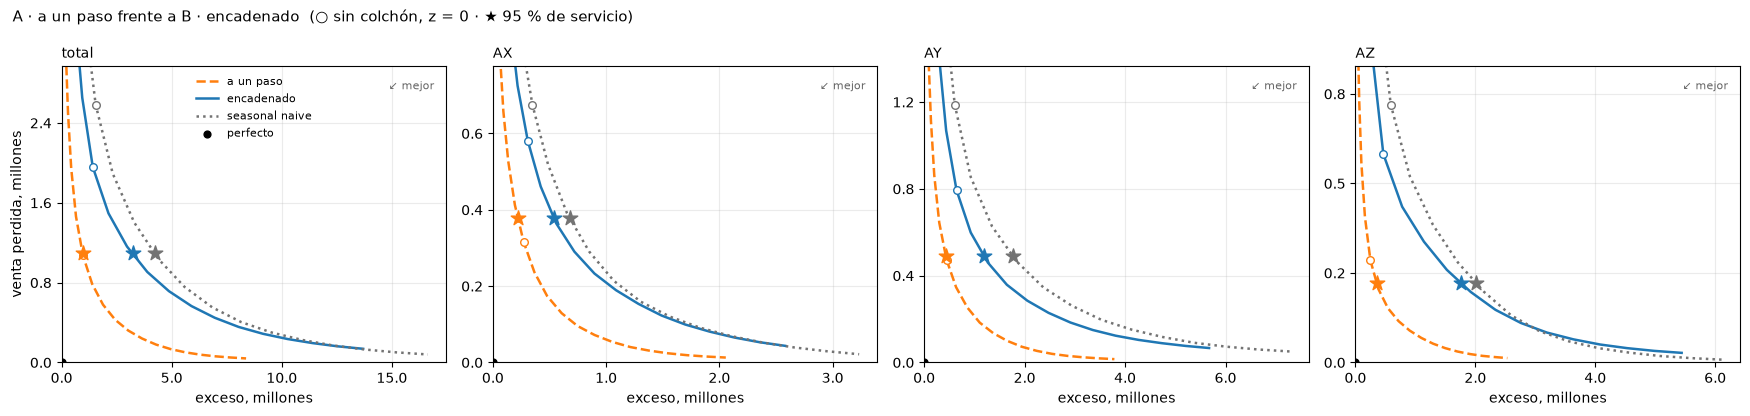

,exceso95_A,exceso95_B,exceso95_extra_B,desajuste0_A,desajuste0_B,desajuste0_extra_B
segment,,,,,,
total,951801.0,3219792.0,2267991.0,2041014.0,3374605.0,1333592.0
AX,221048.0,538681.0,317632.0,587239.0,889018.0,301779.0
AY,429212.0,1188630.0,759418.0,918864.0,1438290.0,519426.0
AZ,356014.0,1766306.0,1410292.0,534911.0,1047297.0,512386.0


Para el mismo 95% de servicio, no renovar el pronóstico (B) exige 2,267,991 más de exceso; sin colchón, su desajuste es 1,333,592 mayor.


In [33]:
marks_ab = pd.concat([marks["A · a un paso"], marks["B · encadenado"]]).drop_duplicates()
fig = plot_tradeoff_curves(curves, ["a un paso", "encadenado", BASE], SEG_ALL, marks_ab, "A · a un paso frente a B · encadenado")
plt.show()
display(ab.round(0))
t = ab.loc["total"]
print(f"Para el mismo {TARGET_SERVICE:.0%} de servicio, no renovar el pronóstico (B) exige {t['exceso95_extra_B']:,.0f} más de exceso; "
      f"sin colchón, su desajuste es {t['desajuste0_extra_B']:,.0f} mayor.")


## Etapa 4 · Impacto por artículo, mayores y menores

**Objetivo:** ver en qué artículos se concentra el dinero que gana o ahorra el CatBoost frente al seasonal naive, y en cuáles no aporta o empeora, en cada escenario (D9).
**Entradas:** `demand`, `sigma`, `FORECASTS`, `SIGMA` (Etapas 1 y 2), `readings` (Etapa 3), `item_metrics` y `forecasts` (nb 05) y `boosting_data` (03b, para los gráficos).
**Salidas:** `item_impact`, una fila por artículo y escenario con la venta perdida y el exceso del CatBoost y del seasonal naive, el impacto (total, en venta perdida y en exceso) y el RMSSE del nb 05; tablas por segmento, de concentración y de mayores y menores; gráficos.

**Decisión:**
- **Punto de comparación:** cada pronóstico con el z que le da el 95 % de servicio en el total (Etapa 3), calculado de nuevo en ese z exacto (no interpolado), así cada artículo se compara en el mismo régimen que la lectura global.
- **Impacto** = desajuste del seasonal naive − desajuste del CatBoost, con desajuste = venta perdida + exceso (D9); positivo = el modelo mejora. Se muestran también sus dos partes, en venta perdida y en exceso, y el impacto como % de la demanda del artículo.
- **Ranking por dinero:** los 10 de mayor y los 10 de menor impacto (lo que pesa en el negocio), con su % de la demanda para ver si el efecto es grande en el artículo o solo por su tamaño, su segmento, su RMSSE del nb 05 y si quedó marcado para revisar.
- **Concentración:** cuántos artículos explican el 50 % y el 80 % del impacto positivo, y cuántos empeoran.
- **Gráficos:** el gráfico del nb 05 (tasas y unidades en el test, a un paso y encadenado) de los 5 de mayor y los 5 de menor impacto de cada escenario, en pantalla.
- **Chequeos:** 517 artículos por escenario; servicio total del CatBoost y del seasonal naive en su z ≈ 95 % (±0,5 puntos); el impacto es la suma de sus dos partes; sin nulos.


In [34]:
from src.metrics import coverage_by_z, seasonal_naive_scale
from src.modeling import plot_forecast_item

TOP_N = 10    # artículos por extremo en las tablas: se leen de un vistazo
PLOT_N = 5    # gráficos por extremo, como la muestra del nb 04 y del nb 05
SERVICE_TOL = 0.005   # el z exacto debe dar el 95 % con ±0,5 puntos (la Etapa 3 interpola entre z vecinos)


In [35]:
def scenario_items(scen, model):
    r = readings[scen].loc["total"]
    z_m, z_b = float(r["z95_modelo"]), float(r["z95_naive"])
    cov_m = coverage_by_z(demand, {model: FORECASTS[model]}, {model: SIGMA[model]}, [z_m]).set_index("item_id")
    cov_b = coverage_by_z(demand, {BASE: FORECASTS[BASE]}, {BASE: SIGMA[BASE]}, [z_b]).set_index("item_id")
    t = cov_m[["demand", "lost", "excess"]].join(cov_b[["lost", "excess"]], lsuffix="_modelo", rsuffix="_naive")
    t["impacto_perdida"] = t["lost_naive"] - t["lost_modelo"]
    t["impacto_exceso"] = t["excess_naive"] - t["excess_modelo"]
    t["impacto"] = t["impacto_perdida"] + t["impacto_exceso"]
    t["impacto_%_demanda"] = 100 * t["impacto"] / t["demand"]
    nb05_item = item_metrics[item_metrics["form"] == model].set_index("item_id")[["rmsse_units", "review"]]
    t = t.join(nb05_item)
    t.insert(0, "cell", t.index.map(demand.groupby("item_id")["cell"].first()))
    service = {"modelo": cov_m["captured"].sum() / cov_m["demand"].sum(), "naive": cov_b["captured"].sum() / cov_b["demand"].sum()}
    return t.assign(scenario=scen, z_modelo=z_m, z_naive=z_b).reset_index(), service

item_impact, service_at_z = [], {}
for scen, model in SCENARIOS.items():
    t, service_at_z[scen] = scenario_items(scen, model)
    item_impact.append(t)
item_impact = pd.concat(item_impact, ignore_index=True)

def concentration(t):
    pos = t[t["impacto"] > 0].sort_values("impacto", ascending=False)
    share = pos["impacto"].cumsum() / pos["impacto"].sum()
    return pd.Series({"articulos": len(t), "mejoran": len(pos), "empeoran": int((t["impacto"] < 0).sum()),
                      "para_50%_del_impacto": int((share < 0.5).sum()) + 1, "para_80%_del_impacto": int((share < 0.8).sum()) + 1,
                      "impacto_total": t["impacto"].sum()})

by_segment = (pd.concat([item_impact, item_impact.assign(cell="total")])
              .groupby(["scenario", "cell"])[["demand", "impacto_perdida", "impacto_exceso", "impacto"]].sum())
by_segment["impacto_%_demanda"] = 100 * by_segment["impacto"] / by_segment["demand"]
conc = item_impact.groupby("scenario").apply(concentration)

# Escala del RMSSE en tasas para los gráficos (misma definición del nb 05).
train_rows = boosting_data[boosting_data["split"] == "train"]
rate_scale = train_rows.groupby(train_rows["item_id"].astype(str))["ratio_raw"].apply(
    lambda r: seasonal_naive_scale(r.to_numpy(float), manifest["snaive_m"]))


/tmp/ipykernel_168993/3783511167.py:6: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  t = cov_m[["demand", "lost", "excess"]].join(cov_b[["lost", "excess"]], lsuffix="_modelo", rsuffix="_naive")
/tmp/ipykernel_168993/3783511167.py:6: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  t = cov_m[["demand", "lost", "excess"]].join(cov_b[["lost", "excess"]], lsuffix="_modelo", rsuffix="_naive")


In [36]:
assert (item_impact.groupby("scenario").size() == n_items).all()
assert item_impact.drop(columns=["review"]).notna().all().all()
assert np.allclose(item_impact["impacto"], item_impact["impacto_perdida"] + item_impact["impacto_exceso"])
for scen, sv in service_at_z.items():
    assert all(abs(v - TARGET_SERVICE) <= SERVICE_TOL for v in sv.values()), (scen, sv)
    print(f"{scen}: servicio en su z del 95 % → CatBoost {sv['modelo']:.2%}, seasonal naive {sv['naive']:.2%}")

print("Impacto por segmento (dinero; positivo = el CatBoost mejora):")
display(by_segment.round({"demand": 0, "impacto_perdida": 0, "impacto_exceso": 0, "impacto": 0, "impacto_%_demanda": 1}))
print("Concentración del impacto:")
display(conc.round(0))


A · a un paso: servicio en su z del 95 % → CatBoost 95.01%, seasonal naive 95.03%
B · encadenado: servicio en su z del 95 % → CatBoost 95.03%, seasonal naive 95.03%
Impacto por segmento (dinero; positivo = el CatBoost mejora):


demand  impacto_perdida  impacto_exceso    impacto  \
scenario       cell                                                            
A · a un paso  AX      7579963.0         -15045.0        550225.0   535181.0   
               AY      9851338.0           7212.0       1325405.0  1332617.0   
               AZ      4424915.0           4380.0       1397081.0  1401461.0   
               total  21856216.0          -3452.0       3272711.0  3269259.0   
B · encadenado AX      7579963.0         -37035.0        216851.0   179816.0   
               AY      9851338.0          58734.0        395819.0   454553.0   
               AZ      4424915.0         -20072.0        397127.0   377055.0   
               total  21856216.0           1626.0       1009798.0  1011424.0   

                      impacto_%_demanda  
scenario       cell                      
A · a un paso  AX                   7.1  
               AY                  13.5  
               AZ                  31.7  
               total               15.0  
B · encadenado AX                   2.4  
               AY                   4.6  
               AZ                   8.5  
               total                4.6

Concentración del impacto:


,articulos,mejoran,empeoran,para_50%_del_impacto,para_80%_del_impacto,impacto_total
scenario,,,,,,
A · a un paso,517.0,490.0,27.0,55.0,179.0,3269259.0
B · encadenado,517.0,374.0,143.0,32.0,127.0,1011424.0


### A · a un paso


A · a un paso: 490 de 517 artículos mejoran y 27 empeoran; 55 artículos explican el 50 % del impacto positivo y 179 el 80 %.
Los 10 de mayor impacto:


,item_id,cell,impacto,impacto_%_demanda,impacto_perdida,impacto_exceso,rmsse_units,review
248,FOODS_3_607,AZ,128767.3,138.5,-5503.7,134271.0,0.2,False
114,FOODS_3_090,AY,114537.6,39.8,-7755.8,122293.4,0.1,False
154,FOODS_3_245,AZ,68829.8,191.3,-884.9,69714.6,0.1,False
207,FOODS_3_455,AZ,65866.0,109.3,-3094.6,68960.5,0.2,False
173,FOODS_3_318,AZ,61577.1,89.6,-4587.5,66164.6,0.1,False
105,FOODS_3_030,AZ,61380.8,146.7,-1329.6,62710.5,0.0,False
163,FOODS_3_281,AZ,58994.0,185.2,-1795.7,60789.7,0.1,False
127,FOODS_3_134,AZ,40284.4,26.6,23062.1,17222.3,0.4,False
291,FOODS_3_787,AZ,38753.9,248.5,-516.6,39270.5,0.1,False
370,HOUSEHOLD_1_053,AY,38453.6,24.1,39652.6,-1199.0,0.4,False


Los 10 de menor impacto:


,item_id,cell,impacto,impacto_%_demanda,impacto_perdida,impacto_exceso,rmsse_units,review
326,HOBBIES_1_179,AX,-650.7,-2.3,-403.7,-247.0,0.8,False
67,FOODS_2_194,AY,-695.1,-1.0,2099.7,-2794.8,1.0,False
193,FOODS_3_399,AY,-1211.8,-1.7,-1432.9,221.1,0.4,False
428,HOUSEHOLD_1_290,AZ,-1284.7,-2.7,-1437.6,152.9,0.9,False
290,FOODS_3_785,AY,-1288.8,-1.0,-4207.3,2918.5,0.7,False
372,HOUSEHOLD_1_056,AZ,-1366.3,-4.4,-822.5,-543.8,0.7,False
230,FOODS_3_534,AX,-1711.1,-4.8,-1242.4,-468.6,0.6,False
404,HOUSEHOLD_1_184,AZ,-2079.4,-3.9,-6257.7,4178.3,1.1,False
109,FOODS_3_069,AZ,-2545.6,-9.5,-3363.0,817.4,1.2,True
156,FOODS_3_252,AX,-7402.8,-4.1,-3569.8,-3833.0,1.6,True


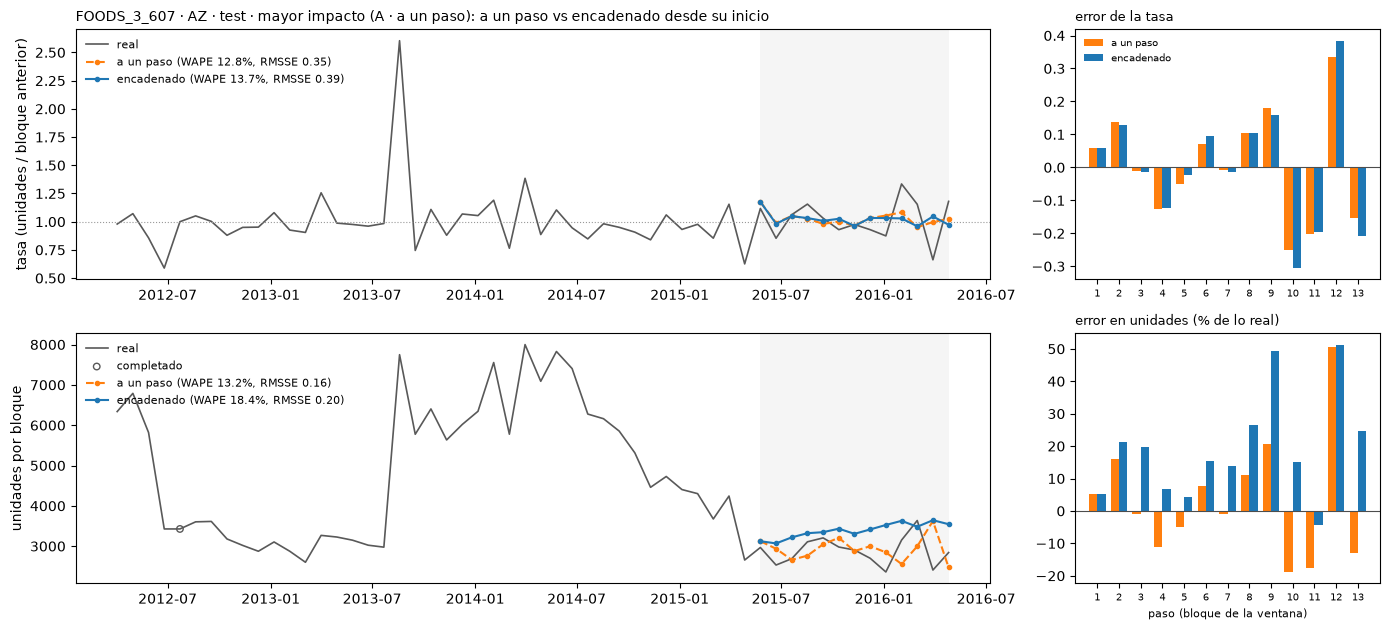

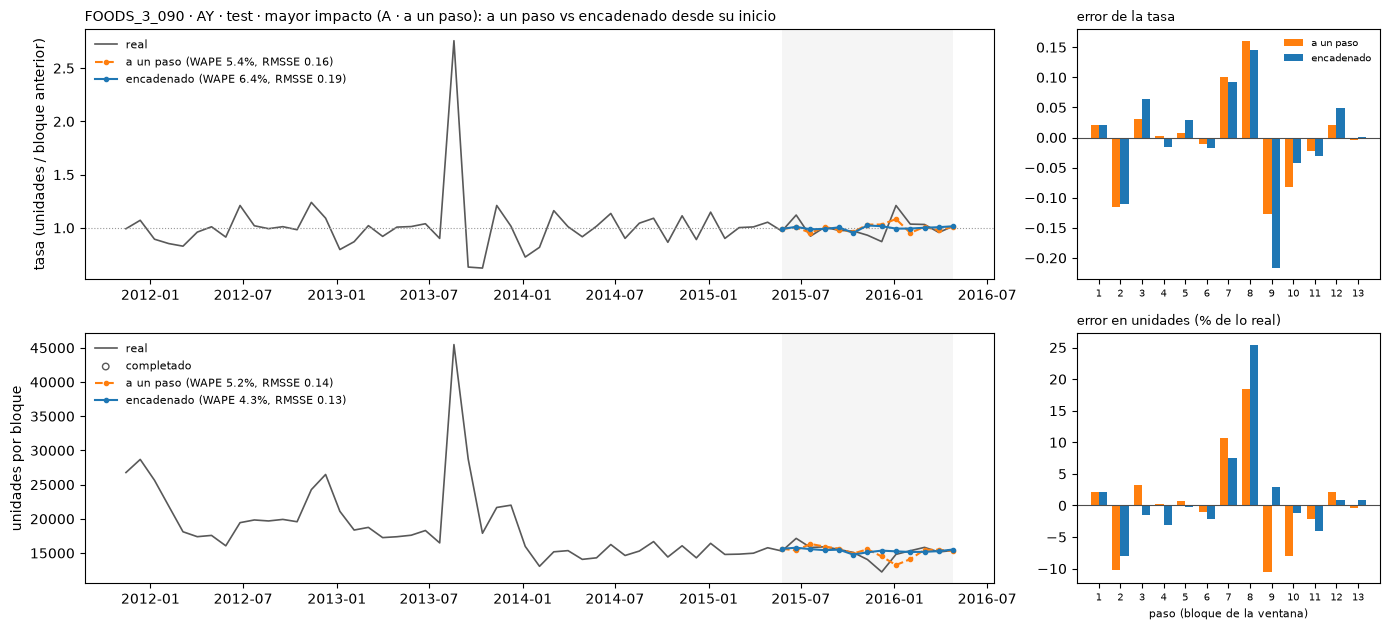

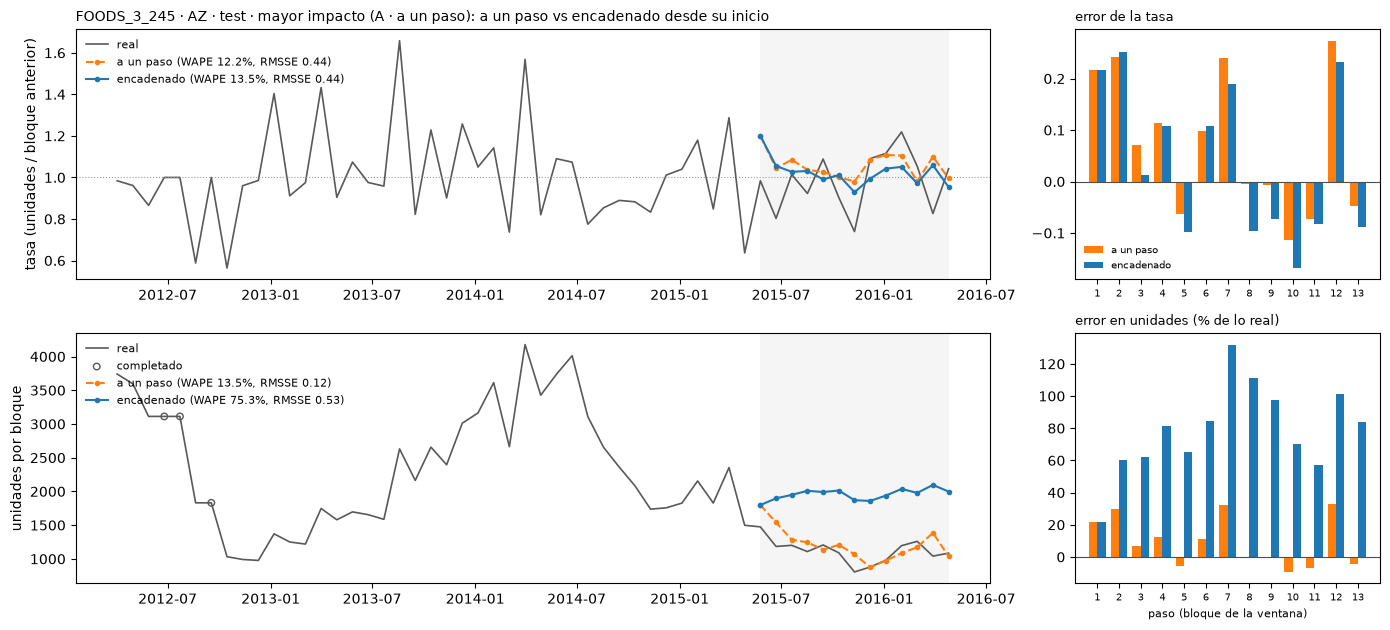

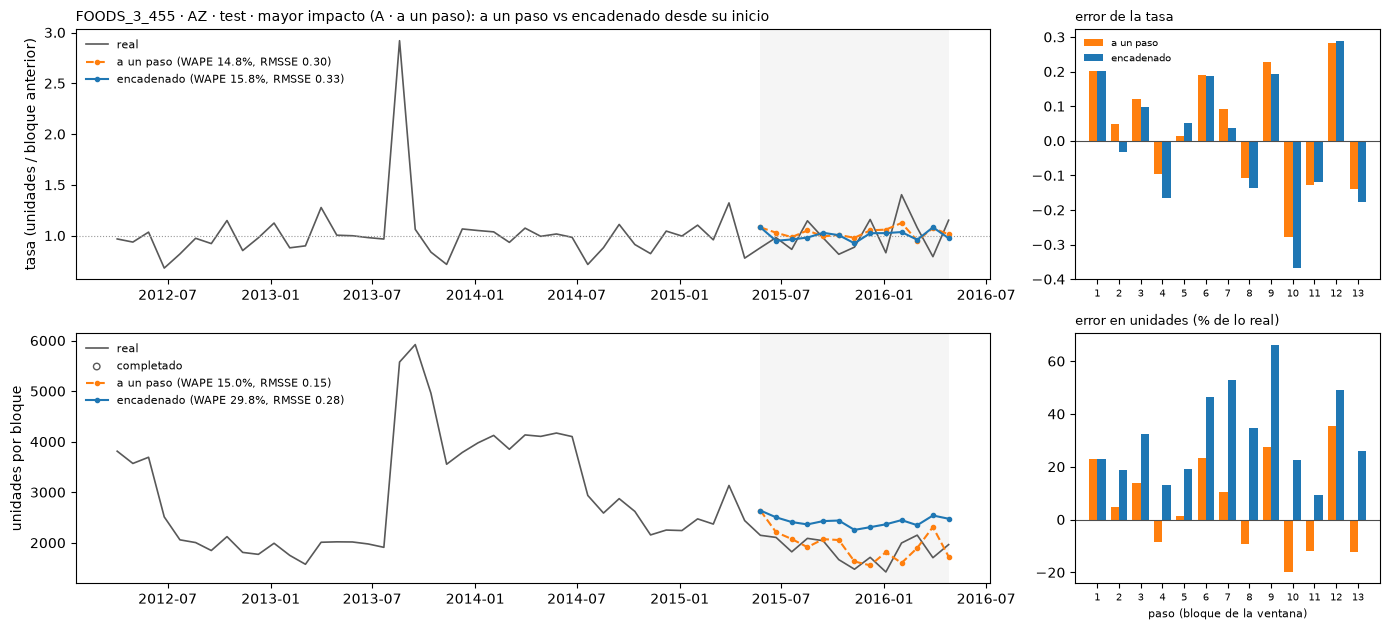

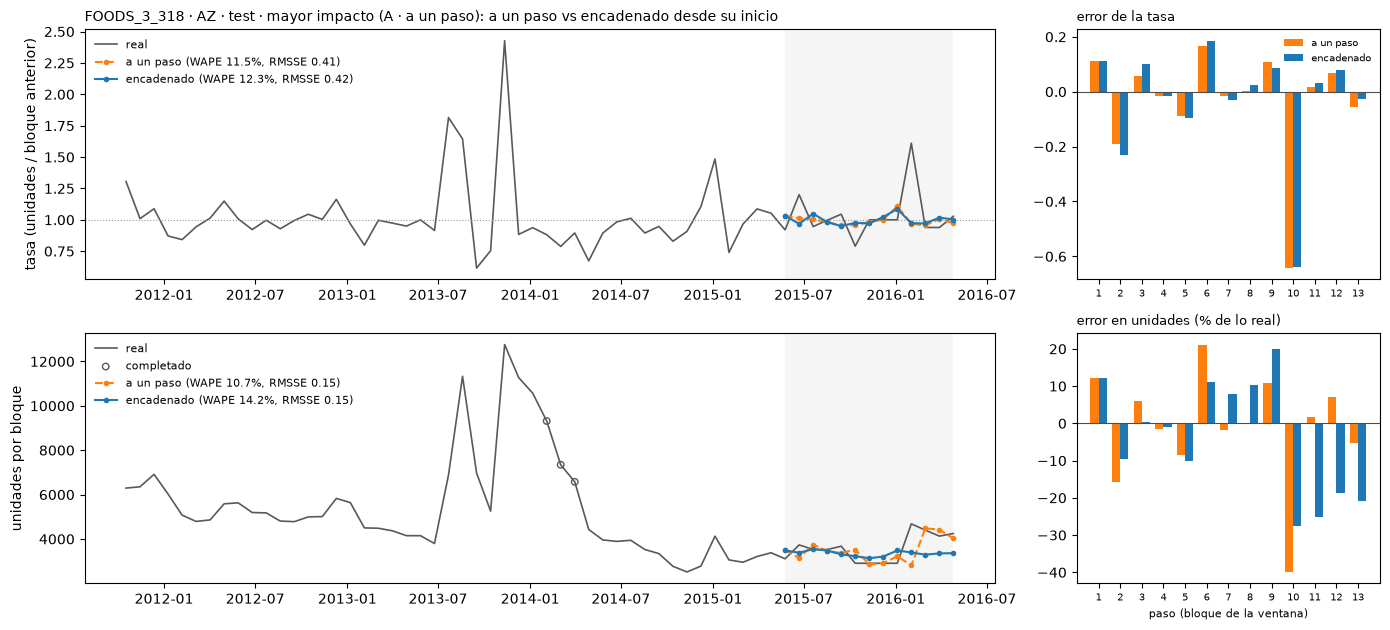

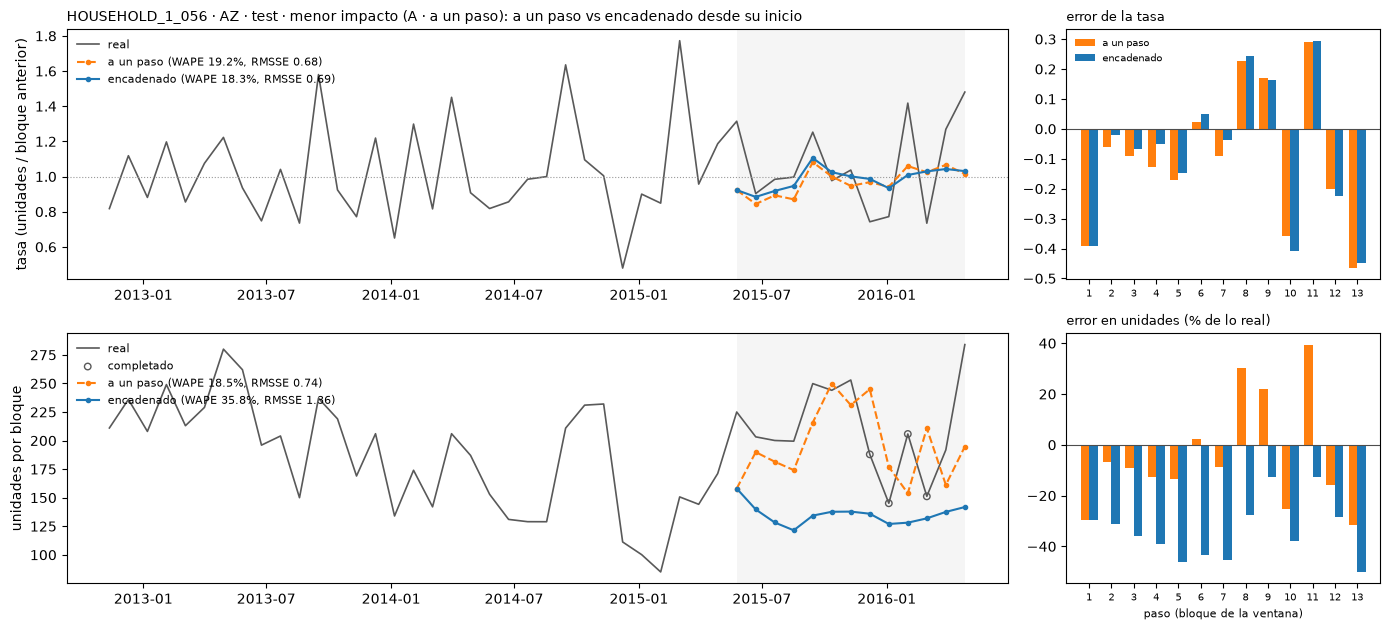

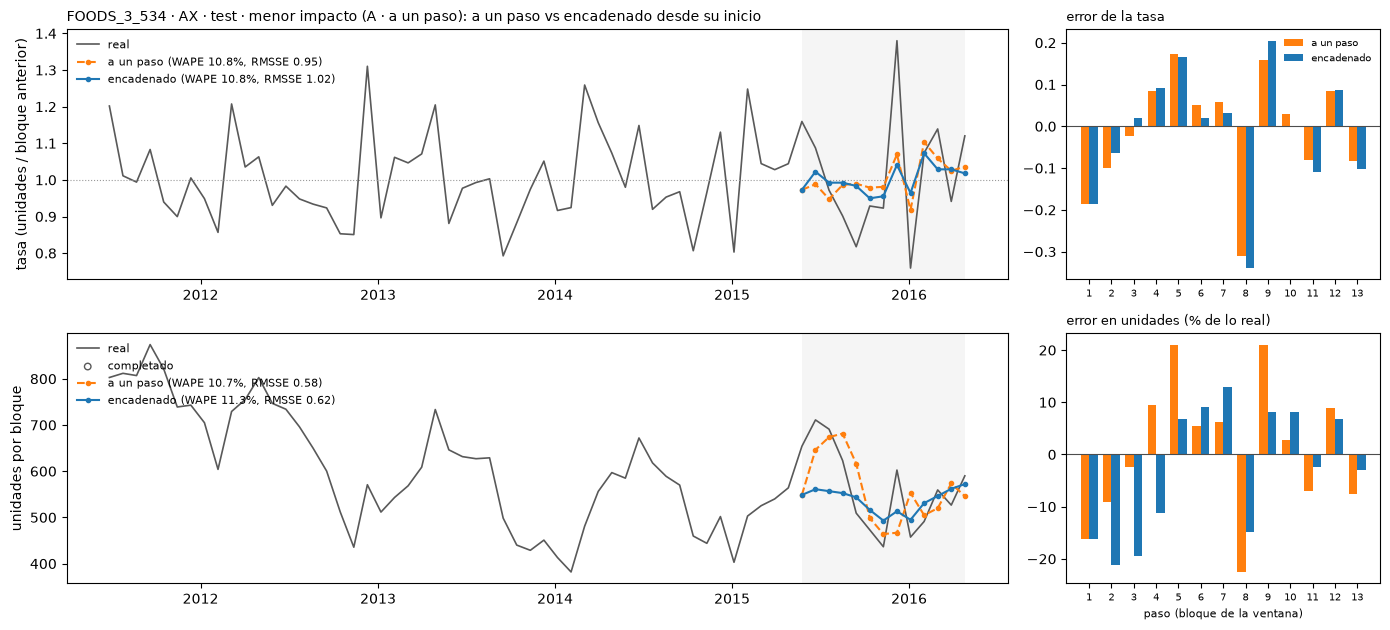

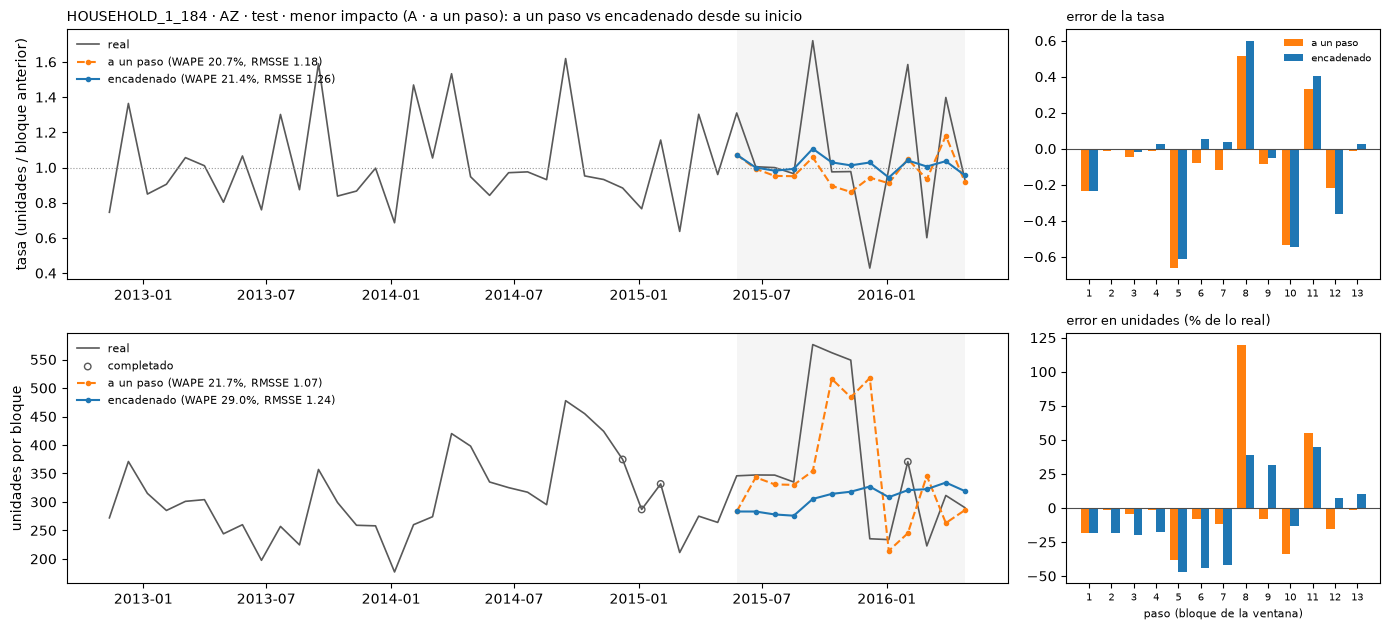

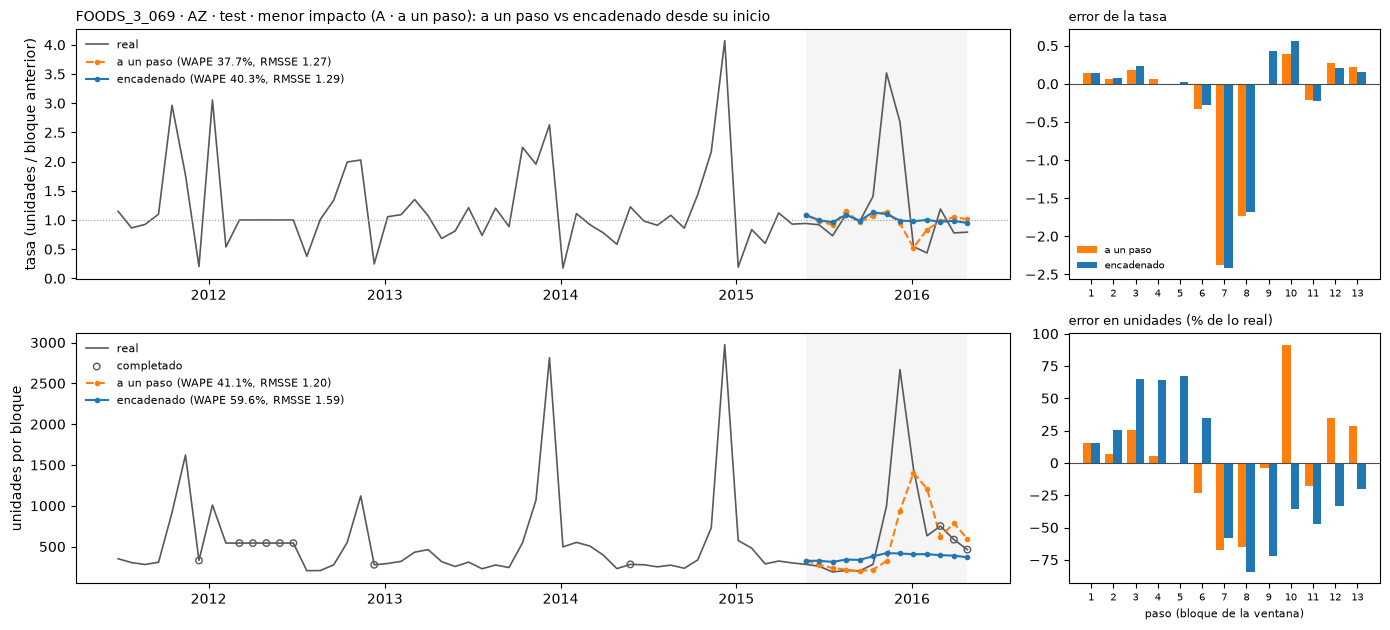

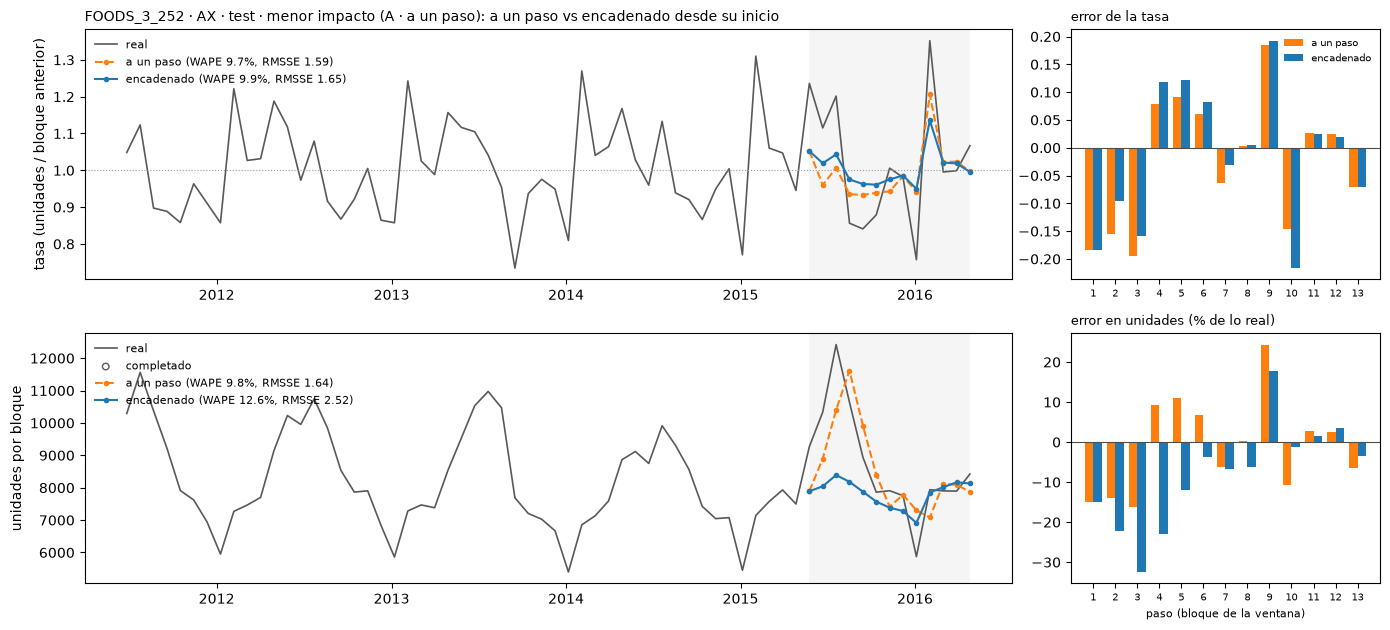

In [37]:
scen = "A · a un paso"
t = item_impact[item_impact["scenario"] == scen].sort_values("impacto", ascending=False)
c = conc.loc[scen]
print(f"{scen}: {int(c['mejoran'])} de {int(c['articulos'])} artículos mejoran y {int(c['empeoran'])} empeoran; "
      f"{int(c['para_50%_del_impacto'])} artículos explican el 50 % del impacto positivo y {int(c['para_80%_del_impacto'])} el 80 %.")
print(f"Los {TOP_N} de mayor impacto:")
display(t.head(TOP_N)[["item_id", "cell", "impacto", "impacto_%_demanda", "impacto_perdida", "impacto_exceso", "rmsse_units", "review"]].round(1))
print(f"Los {TOP_N} de menor impacto:")
display(t.tail(TOP_N)[["item_id", "cell", "impacto", "impacto_%_demanda", "impacto_perdida", "impacto_exceso", "rmsse_units", "review"]].round(1))
for label, items in (("mayor", t.head(PLOT_N)["item_id"]), ("menor", t.tail(PLOT_N)["item_id"])):
    for item in items:
        fig = plot_forecast_item(boosting_data, forecasts, item, float(rate_scale[item]), float(rmsse_scale[item]),
                                 splits=("train", "test"), window_label=f"test · {label} impacto ({scen})")
        fig.tight_layout()
        plt.show()


### B · encadenado


B · encadenado: 374 de 517 artículos mejoran y 143 empeoran; 32 artículos explican el 50 % del impacto positivo y 127 el 80 %.
Los 10 de mayor impacto:


,item_id,cell,impacto,impacto_%_demanda,impacto_perdida,impacto_exceso,rmsse_units,review
631,FOODS_3_090,AY,113318.8,39.4,-1151.6,114470.5,0.1,False
765,FOODS_3_607,AZ,85704.8,92.2,0.0,85704.8,0.2,False
724,FOODS_3_455,AZ,32293.3,53.6,0.0,32293.3,0.3,False
622,FOODS_3_030,AZ,29421.7,70.3,0.0,29421.7,0.1,False
690,FOODS_3_318,AZ,28923.7,42.1,0.0,28923.7,0.2,False
680,FOODS_3_281,AZ,27624.6,86.7,0.0,27624.6,0.1,False
671,FOODS_3_245,AZ,26758.8,74.4,0.0,26758.8,0.5,False
905,HOUSEHOLD_1_110,AY,26705.1,16.3,-2696.7,29401.8,0.2,False
887,HOUSEHOLD_1_053,AY,24913.9,15.6,25364.5,-450.7,1.5,False
808,FOODS_3_787,AZ,20029.7,128.5,0.0,20029.7,0.4,False


Los 10 de menor impacto:


,item_id,cell,impacto,impacto_%_demanda,impacto_perdida,impacto_exceso,rmsse_units,review
954,HOUSEHOLD_1_327,AY,-7672.2,-33.7,184.4,-7856.6,1.3,False
657,FOODS_3_202,AX,-9201.7,-2.9,-10249.0,1047.3,1.0,False
673,FOODS_3_252,AX,-9841.5,-5.5,-8510.2,-1331.3,2.5,True
525,FOODS_1_055,AZ,-11119.6,-19.8,1973.5,-13093.1,1.6,False
626,FOODS_3_069,AZ,-11511.3,-43.0,-2889.5,-8621.7,1.6,False
547,FOODS_1_180,AZ,-13356.2,-28.4,0.0,-13356.2,1.4,False
644,FOODS_3_134,AZ,-15479.2,-10.2,25829.7,-41308.9,0.9,False
790,FOODS_3_727,AY,-17684.6,-47.1,360.2,-18044.8,0.2,False
719,FOODS_3_432,AZ,-22080.7,-99.2,0.0,-22080.7,0.1,False
785,FOODS_3_702,AZ,-29176.0,-31.8,0.0,-29176.0,1.9,True


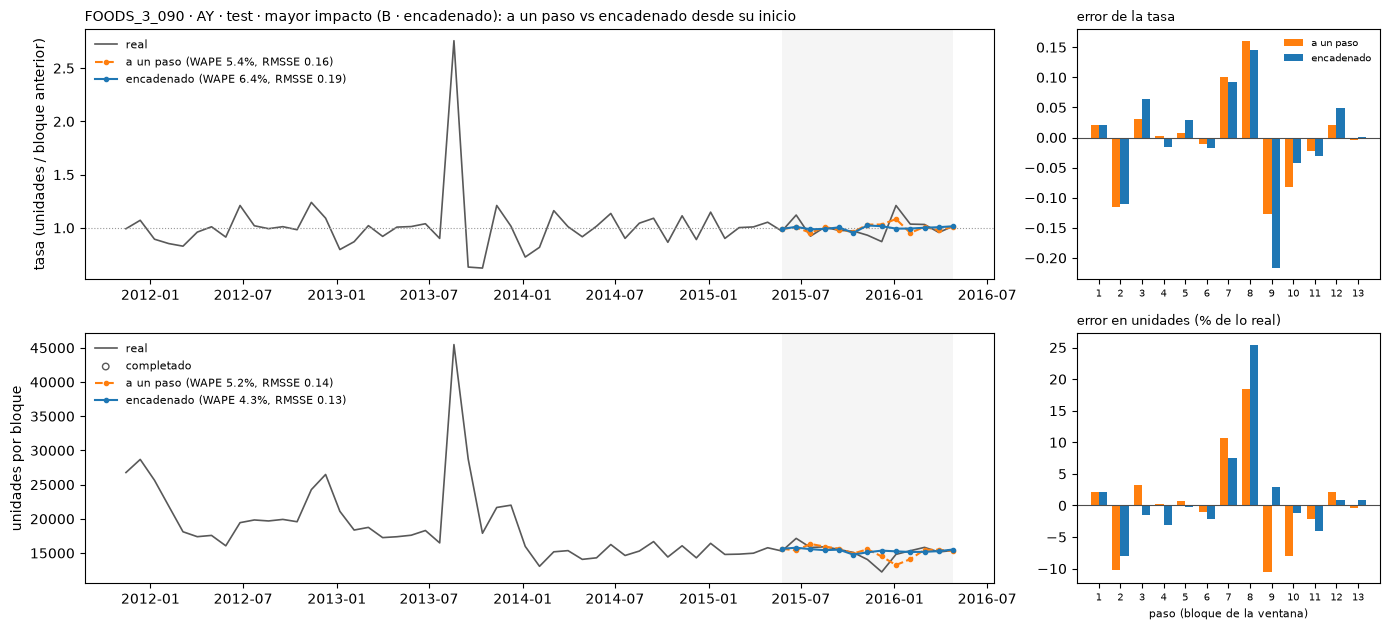

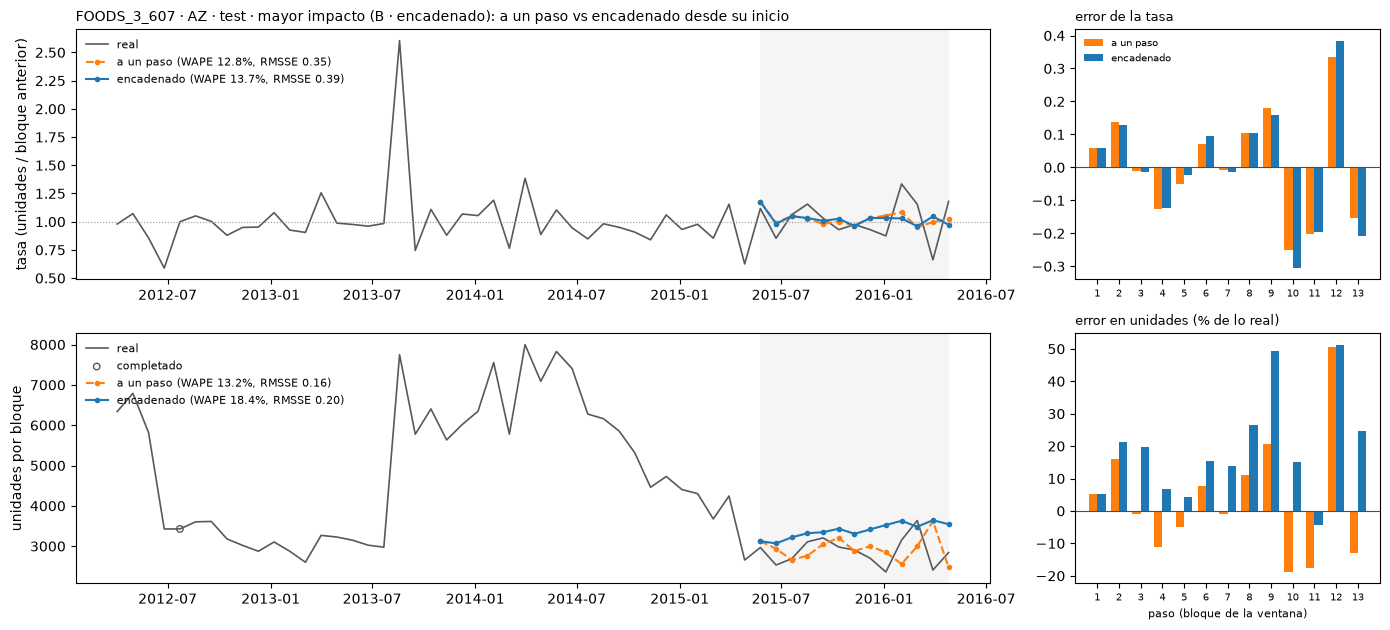

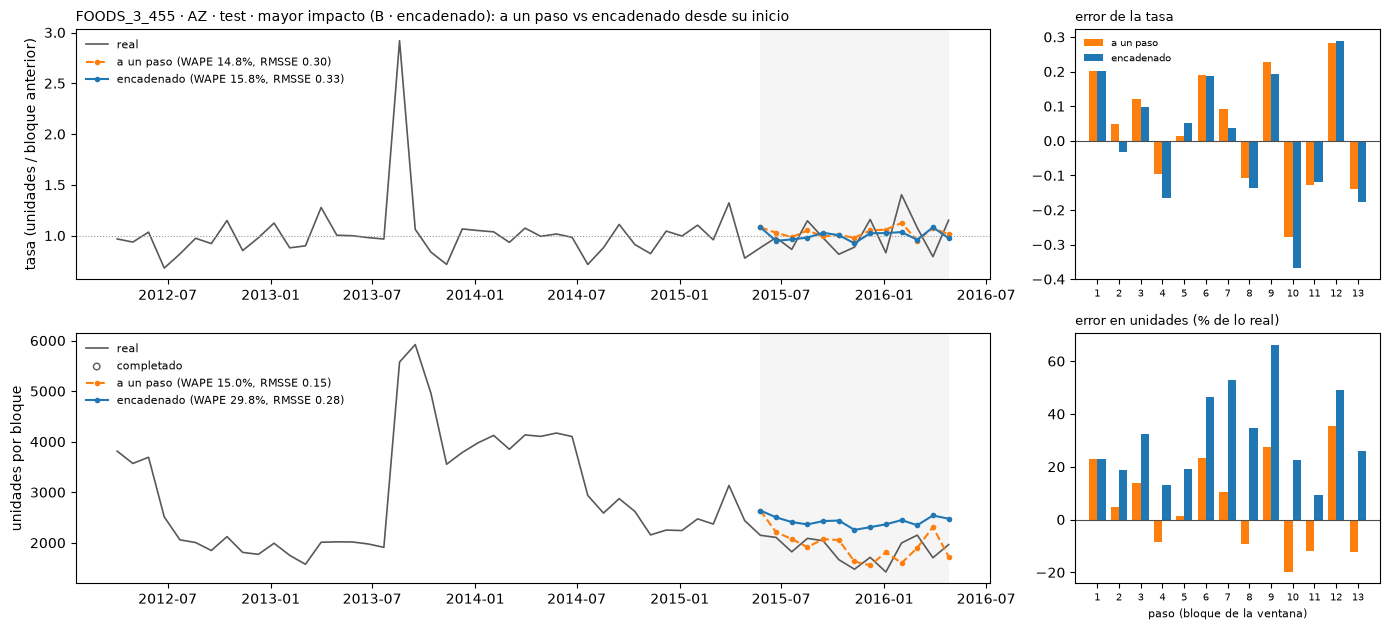

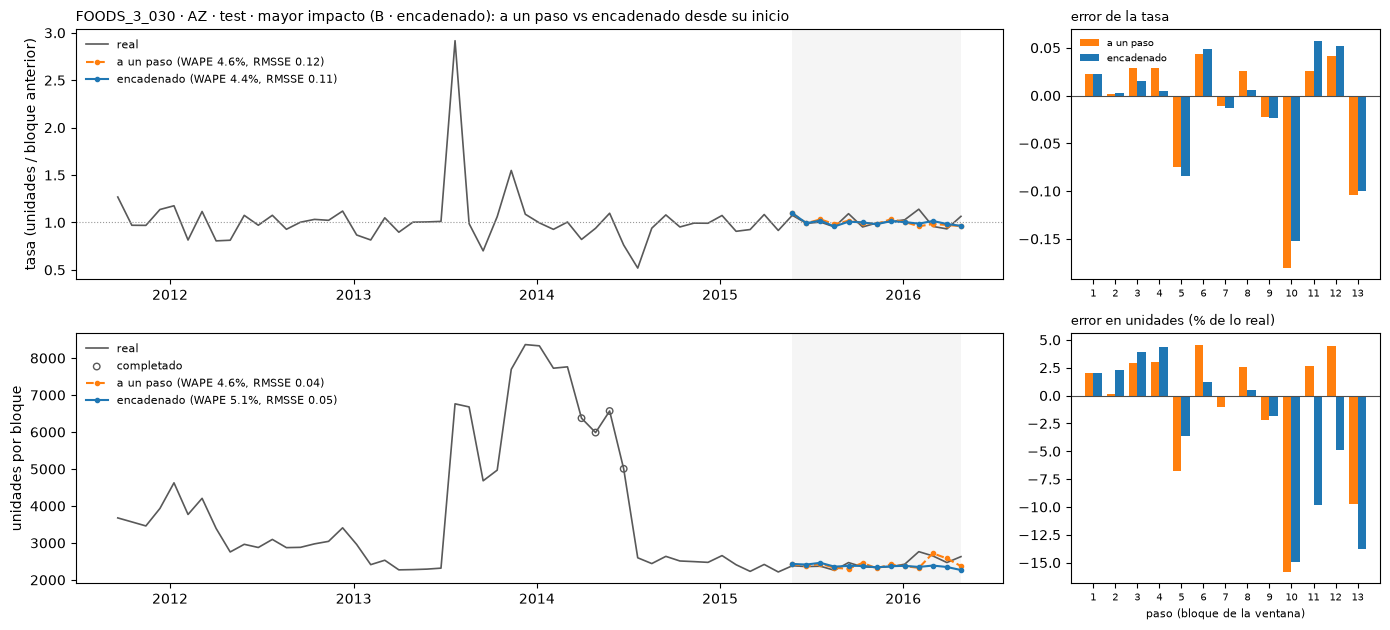

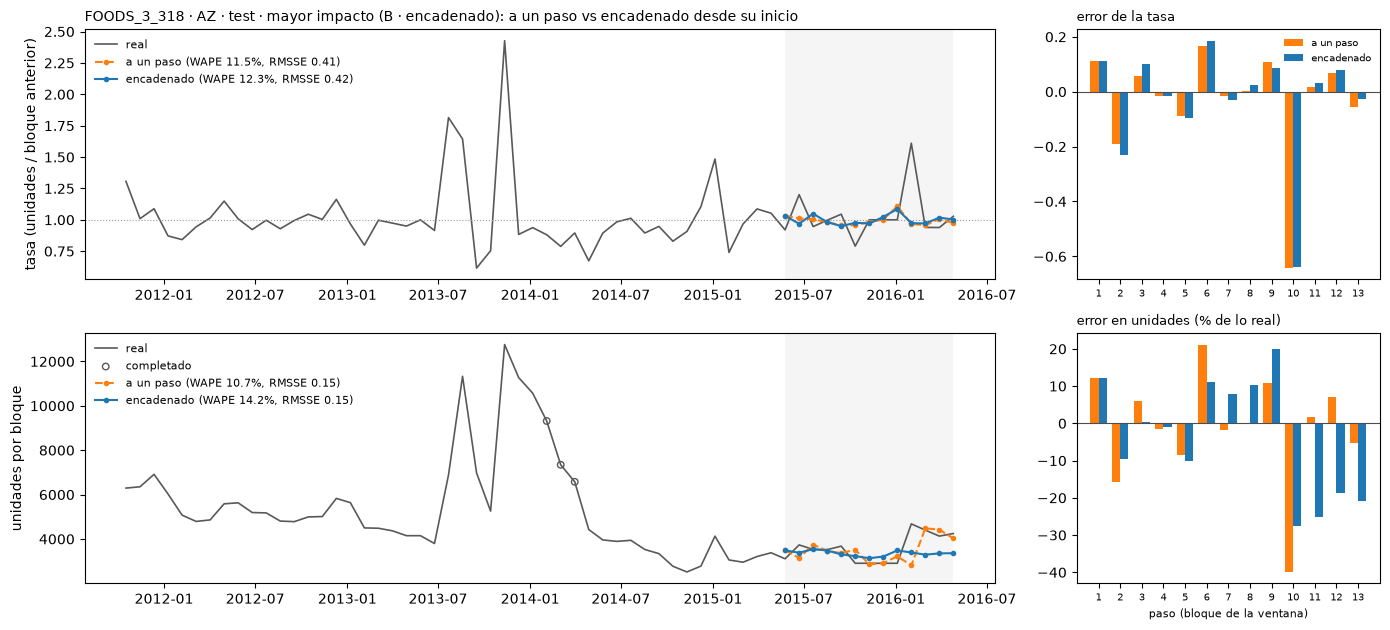

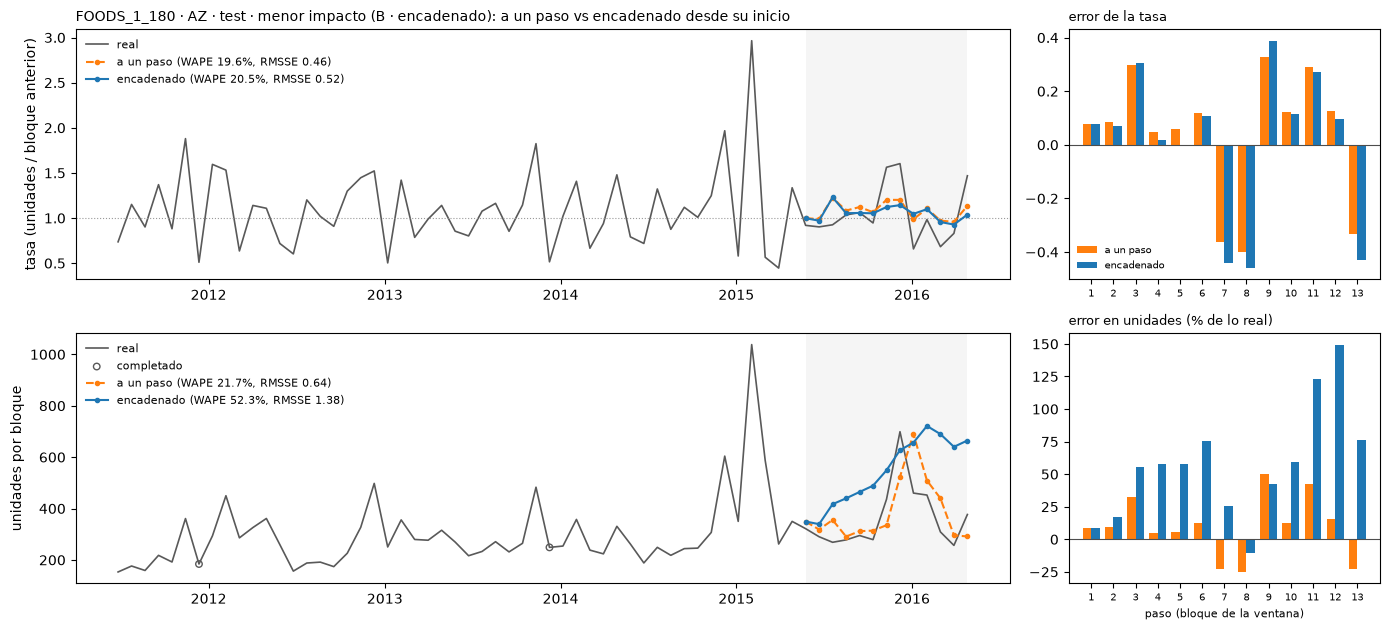

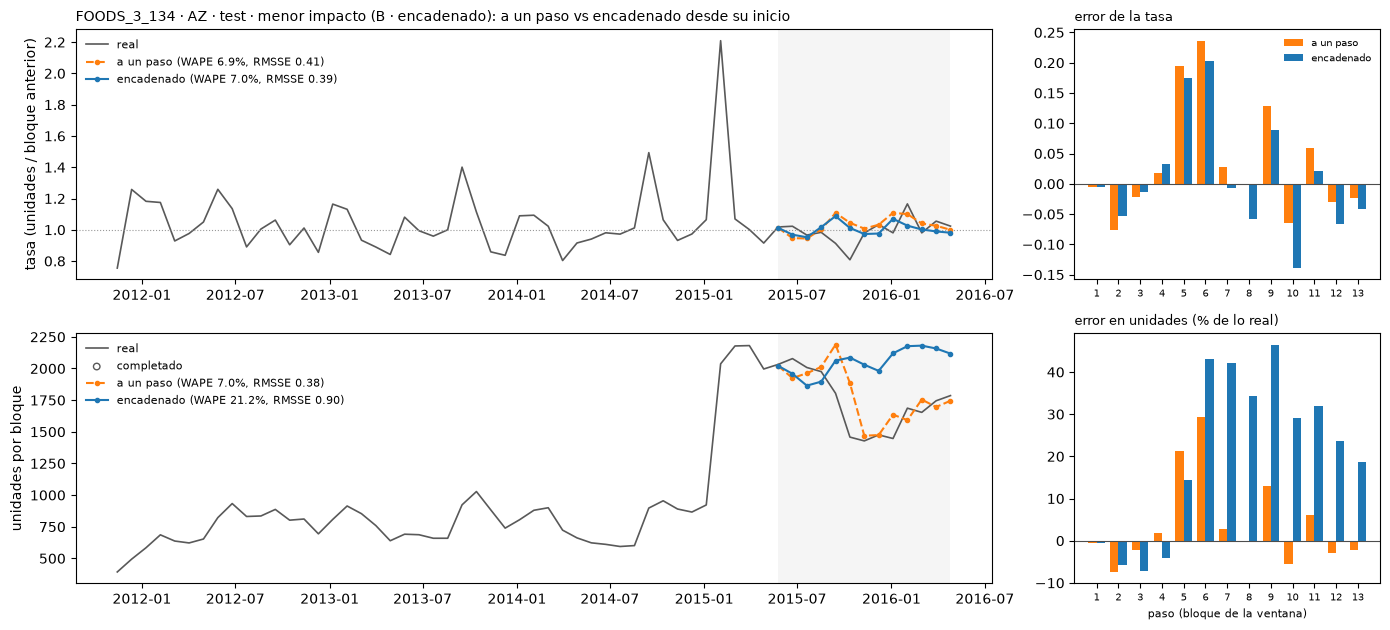

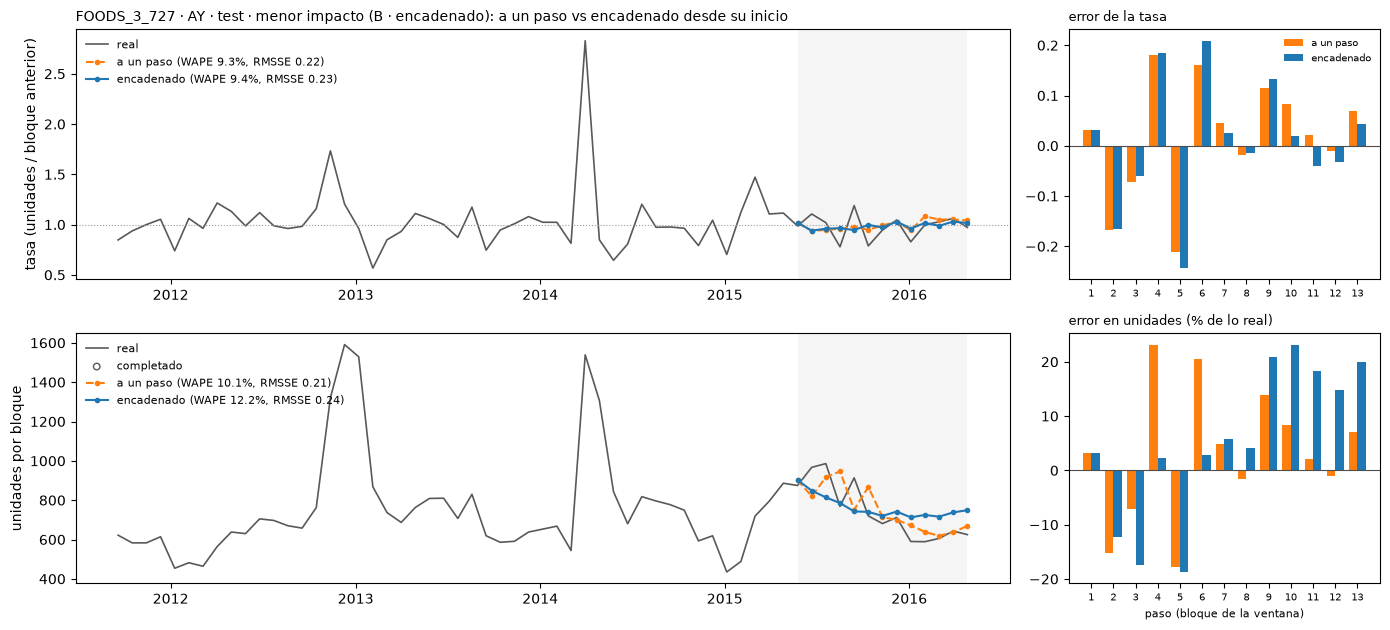

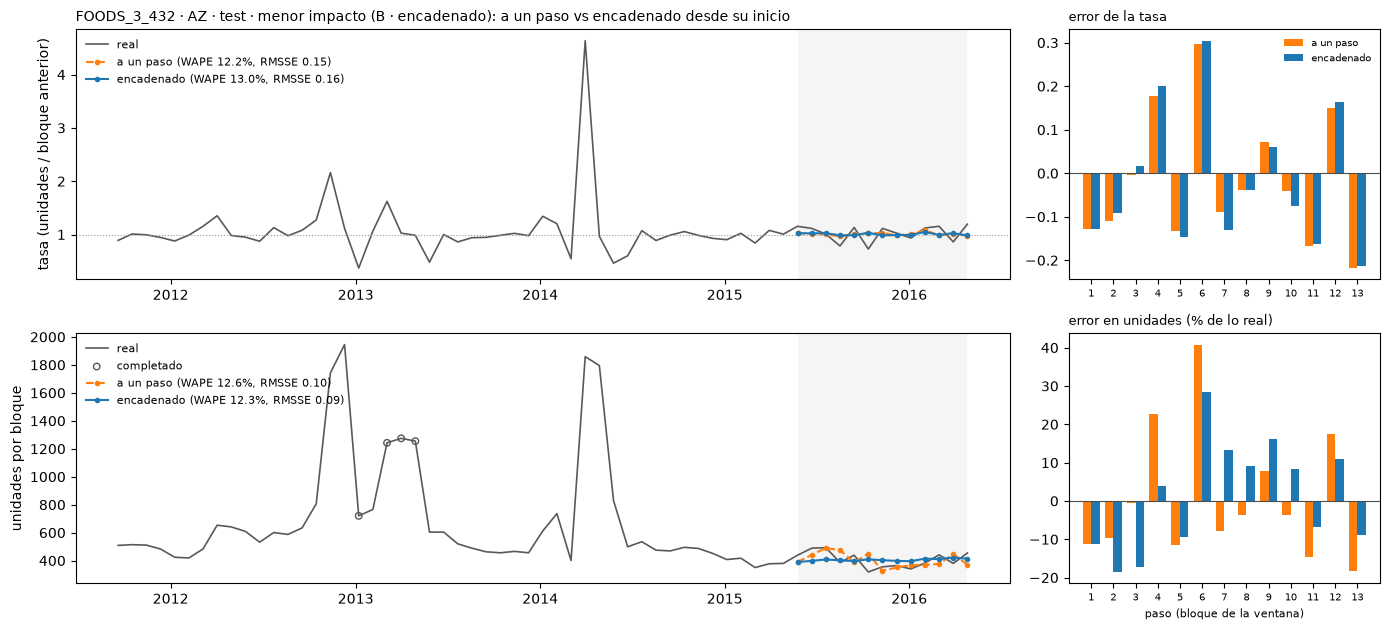

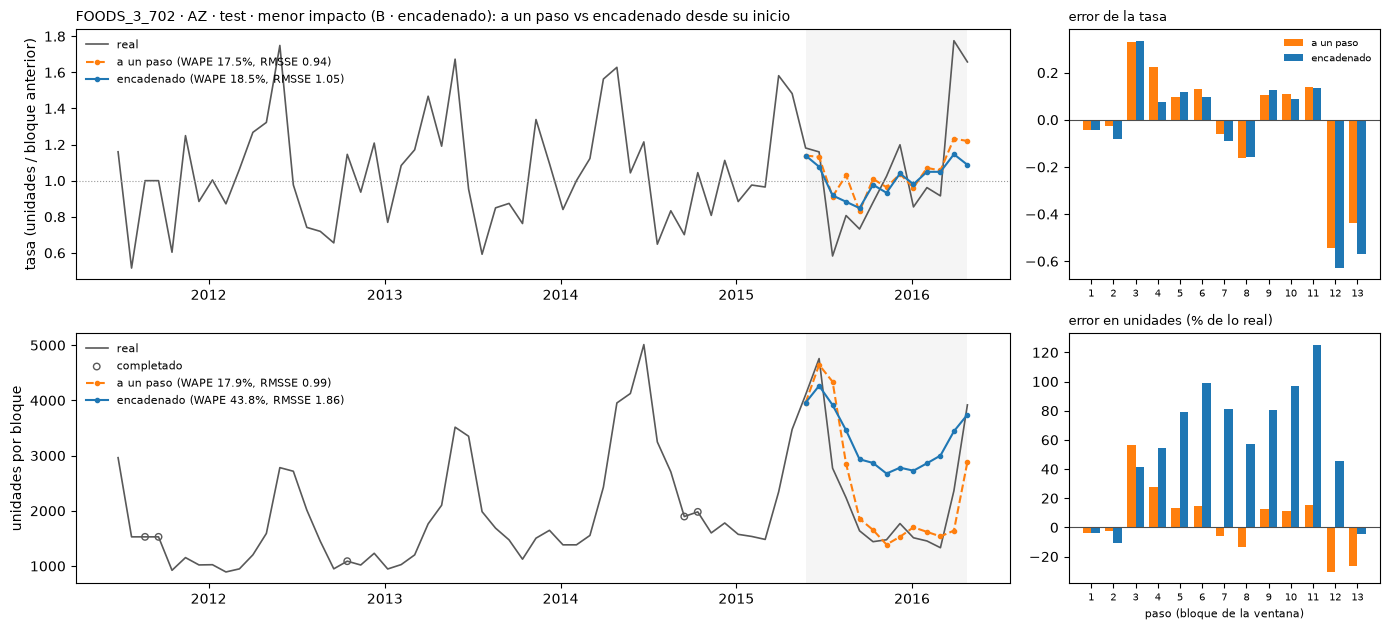

In [38]:
scen = "B · encadenado"
t = item_impact[item_impact["scenario"] == scen].sort_values("impacto", ascending=False)
c = conc.loc[scen]
print(f"{scen}: {int(c['mejoran'])} de {int(c['articulos'])} artículos mejoran y {int(c['empeoran'])} empeoran; "
      f"{int(c['para_50%_del_impacto'])} artículos explican el 50 % del impacto positivo y {int(c['para_80%_del_impacto'])} el 80 %.")
print(f"Los {TOP_N} de mayor impacto:")
display(t.head(TOP_N)[["item_id", "cell", "impacto", "impacto_%_demanda", "impacto_perdida", "impacto_exceso", "rmsse_units", "review"]].round(1))
print(f"Los {TOP_N} de menor impacto:")
display(t.tail(TOP_N)[["item_id", "cell", "impacto", "impacto_%_demanda", "impacto_perdida", "impacto_exceso", "rmsse_units", "review"]].round(1))
for label, items in (("mayor", t.head(PLOT_N)["item_id"]), ("menor", t.tail(PLOT_N)["item_id"])):
    for item in items:
        fig = plot_forecast_item(boosting_data, forecasts, item, float(rate_scale[item]), float(rmsse_scale[item]),
                                 splits=("train", "test"), window_label=f"test · {label} impacto ({scen})")
        fig.tight_layout()
        plt.show()


## Etapa 5 · Guardado y cierre

**Objetivo:** dejar en disco el impacto para armar el informe final en `reports/` sin recalcular (D10).
**Entradas:** `curves`, `readings`, `ab` (Etapa 3); `item_impact`, `by_segment` y `conc` (Etapa 4).
**Salidas:** `data/interim/nb06_impact/` con:
- `curves.parquet`: segmento × pronóstico × z, con demanda, venta capturada, perdida, exceso, bloques cortos y servicio.
- `readings.parquet`: lecturas por escenario y segmento (95 % de servicio, z = 0, recuperación de lo alcanzable).
- `ab.parquet`: A frente a B por segmento.
- `item_impact.parquet`: impacto por artículo y escenario.
- `by_segment.parquet` y `concentration.parquet`: impacto por segmento y concentración, por escenario.
- `manifest.json`: objetivo de servicio, valores de z, origen (nb 05 y nb 03b), demanda total del test en dinero, cifras principales y versiones.

**Decisión:** `save_tables` (Parquet + manifiesto) con candado: si lo guardado es igual no escribe; si es distinto se detiene salvo `OVERWRITE = True`. Se suman a lo previsto en D10 las lecturas, A frente a B, el impacto por segmento y la concentración: son tablas pequeñas y el informe las usa tal cual. **Chequeo:** lo leído de disco es igual a lo que está en memoria.


In [39]:
from src.data import save_tables


In [40]:
readings_table = pd.concat(readings, names=["scenario", "segment"]).reset_index()
headline = {scen: {"ahorro_exceso95": float(r.loc["total", "ahorro_exceso95"]),
                   "ahorro_exceso95_%": float(r.loc["total", "ahorro_exceso95_%"]),
                   "venta_recuperada_igual_exceso": float(r.loc["total", "venta_recuperada_igual_exceso"]),
                   "recupera0_%": float(r.loc["total", "recupera0_%"])}
            for scen, r in readings.items()}
out_manifest = {
    "target_service": TARGET_SERVICE,
    "z_values": [float(z) for z in Z_VALUES],
    "total_demand": float(total_demand),
    "headline": headline,
    "ab_exceso95_extra_B": float(ab.loc["total", "exceso95_extra_B"]),
    "source": {"nb05_saved_at": nb05_manifest["saved_at"], "nb03b_saved_at": manifest["saved_at"]},
    "seed": SEED, "n_items": int(n_items),
    "versions": {"python": platform.python_version(), **{lib: version(lib) for lib in LIBS}},
}
tables = {"curves": curves, "readings": readings_table, "ab": ab.reset_index(), "item_impact": item_impact,
          "by_segment": by_segment.reset_index(), "concentration": conc.reset_index()}
saved = save_tables(OUT_DIR, tables, out_manifest, overwrite=OVERWRITE)


In [41]:
loaded, loaded_manifest = load_tables(OUT_DIR)
assert set(loaded) == set(tables)
for name, df in tables.items():
    pd.testing.assert_frame_equal(loaded[name].reset_index(drop=True), df.reset_index(drop=True), check_dtype=False)
assert loaded_manifest["n_items"] == n_items and np.isclose(loaded_manifest["total_demand"], total_demand)

display(pd.DataFrame({"archivo": [str(p) for p in saved], "KB": [round(p.stat().st_size / 1024, 1) for p in saved]}))
print(f"guardado: {loaded_manifest['saved_at']}")


,archivo,KB
0,data/interim/nb06_impact/curves.parquet,14.2
1,data/interim/nb06_impact/readings.parquet,10.2
2,data/interim/nb06_impact/ab.parquet,4.9
3,data/interim/nb06_impact/item_impact.parquet,92.9
4,data/interim/nb06_impact/by_segment.parquet,4.9
5,data/interim/nb06_impact/concentration.parquet,4.8
6,data/interim/nb06_impact/manifest.json,1.5


guardado: 2026-11-10T17:20:15


## Cierre

**Qué se midió:** cuánto dinero gana o ahorra el negocio al reponer con el CatBoost frente al seasonal naive en el año de test, contra la demanda tratada y a precio de venta: venta capturada, venta perdida y exceso (plata inmovilizada), en dos escenarios: **A · a un paso** (se vuelve a pronosticar cada mes, como en producción) y **B · encadenado** (13 bloques de una vez).

**Cómo leerlo:** al mismo nivel de servicio, el ahorro es el exceso que deja de inmovilizarse; con el mismo exceso, la venta recuperada es la que se deja de perder. A frente a B dice cuánto vale renovar el pronóstico cada mes. El resumen de la celda siguiente sale de lo guardado.

**Advertencias para el informe:** es una estimación sobre datos históricos (backtesting), no un efecto causal medido en operación; la demanda tratada es una estimación en los bloques con quiebre (Etapa 1); cada bloque se evalúa por separado, sin tiempos de entrega ni arrastre de inventario; los montos son a precio de venta (no hay costo ni margen); el agregado suma las 10 tiendas, lo que supone que el inventario se comparte entre ellas.

**Para el informe final (`reports/`):** carga `data/interim/nb06_impact/` y `data/interim/nb05_test/`; no vuelve a calcular nada.


In [42]:
h = loaded_manifest["headline"]
print(f"Demanda del test: {loaded_manifest['total_demand']:,.0f} · objetivo de servicio {loaded_manifest['target_service']:.0%}")
for scen, v in h.items():
    print(f"{scen}: libera {v['ahorro_exceso95']:,.0f} de exceso ({v['ahorro_exceso95_%']:.1f} %) frente al seasonal naive; "
          f"con su mismo exceso recupera {v['venta_recuperada_igual_exceso']:,.0f} de venta; sin colchón recupera el "
          f"{v['recupera0_%']:.1f} % de lo alcanzable.")
print(f"Renovar el pronóstico cada mes (A frente a B) ahorra {loaded_manifest['ab_exceso95_extra_B']:,.0f} de exceso al mismo servicio.")
display(loaded["concentration"].set_index("scenario").round(0))


Demanda del test: 21,856,216 · objetivo de servicio 95%
A · a un paso: libera 3,276,162 de exceso (77.5 %) frente al seasonal naive; con su mismo exceso recupera 907,452 de venta; sin colchón recupera el 50.6 % de lo alcanzable.
B · encadenado: libera 1,008,171 de exceso (23.8 %) frente al seasonal naive; con su mismo exceso recupera 251,611 de venta; sin colchón recupera el 18.3 % de lo alcanzable.
Renovar el pronóstico cada mes (A frente a B) ahorra 2,267,991 de exceso al mismo servicio.


,articulos,mejoran,empeoran,para_50%_del_impacto,para_80%_del_impacto,impacto_total
scenario,,,,,,
A · a un paso,517.0,490.0,27.0,55.0,179.0,3269259.0
B · encadenado,517.0,374.0,143.0,32.0,127.0,1011424.0
